# Variational inference, ELBO, VAE
### Seminar at ИППИ РАН · Computational notes

The main reference is D. P. Kingma and M. Welling, *Auto-Encoding Variational Bayes*, arXiv:1312.6114v11, hereafter **[KW]**. The notation follows its Sections 2–3 and Appendices B–C. Equation numbers prefixed by “KW” refer to that paper. The accompanying Russian notes contain the board derivations and a discussion of assumptions.

The notebook proceeds from an exactly solvable latent-variable model to a neural VAE, then to supervised conditional models. The last step is an **extension**, not an experiment from [KW]. The supervised constructions are related to Sohn, Lee and Yan (2015) and Kingma et al. (2014); full references appear at the end.

All displayed results are produced by the code below. The digit experiment uses the **8 × 8 UCI digits distributed with scikit-learn**, not MNIST. This small, offline dataset makes the demonstration independent of a network connection. It is a teaching experiment, not a reproduction of the numerical results in [KW].

**Execution.** Restart the kernel and run the cells in order. `TRAIN = True` fits all models on `DEVICE` and saves checkpoints. The default selects CUDA when available and otherwise uses the CPU; set `DEVICE = torch.device("cpu")` to force CPU execution. With the accompanying `checkpoints/` directory, `TRAIN = False` restores the fitted models on the selected device. The saved notebook contains a CPU reference run. No data download, GPU, account, or external service is required. The `figures/` directory and `results.json` are generated outputs; the notebook does not read either of them as inputs.

NumPy, SciPy, scikit-learn, and the small algebraic checks run on the CPU. Neural models, their data, latent noise, random generators, and numerical integration tensors use `DEVICE`. Arrays passed to plotting and scikit-learn are explicitly copied to the CPU. The CUDA path has been revised but was not hardware-tested in the validation environment. CPU and CUDA runs need not produce identical numerical results, even with the same seed.

## 0. Notation and numerical setup

| Symbol | Meaning |
|:---|:---|
| $X=\{x^{(i)}\}_{i=1}^{N}$ | Observed dataset in [KW]; $i$ indexes observations. |
| $D$ | Number of observed coordinates; $x\in\mathbb R^D$ or $\{0,1\}^D$. |
| $z\in\mathbb R^J$ | Continuous latent variable; $J$ is its dimension. |
| $\theta,\phi$ | Generative-model and inference-network parameters, respectively. |
| $p_\theta(z),p_\theta(x\mid z)$ | Prior and observation model (decoder). |
| $q_\phi(z\mid x)$ | Variational posterior (encoder), not a prior. |
| $\mu^{(i)},\sigma^{(i)}$ | Encoder mean and **standard deviation**; $s^{(i)}=\log(\sigma^{(i)})^2$ is the log variance. |
| $\epsilon\sim\mathcal N(0,I_J)$ | Parameter-independent noise; $I_J$ is the $J\times J$ identity. |
| $L,M$ | Number of latent draws per observation and minibatch size. |
| $\mathcal L,\widetilde{\mathcal L}$ | Exact ELBO and its Monte Carlo estimate. |

All logarithms are natural. Likelihoods of real-valued observations are **densities**, so their log values need not be negative. All losses are per observation, with event coordinates summed, not averaged. All trained weights are point estimates: this notebook does not infer a posterior over neural-network parameters.

In [1]:
from __future__ import annotations

import os
# Configure deterministic CUDA matrix products before importing torch / initializing CUDA.
# After changing DEVICE or this setting, restart the kernel and run all cells.
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import copy
import hashlib
import json
import math
import platform
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy import integrate, optimize, special, stats
import sklearn
from sklearn.datasets import load_digits, make_moons
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
from torch import nn
from torch.nn import functional as F
from IPython.display import display

SEED = 1729
TRAIN = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    if not torch.cuda.is_available():
        raise RuntimeError("CUDA is unavailable. Select DEVICE = torch.device('cpu').")
    if os.environ.get("CUBLAS_WORKSPACE_CONFIG") not in {":4096:8", ":16:8"}:
        raise RuntimeError("Set CUBLAS_WORKSPACE_CONFIG=:4096:8 before CUDA initialization, then restart the kernel.")
    torch.backends.cudnn.benchmark = False
# Two threads avoid oversubscription on a laptop or a shared notebook server.
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
np.random.seed(SEED)
torch.manual_seed(SEED)

FIG_DIR = Path("figures")
CKPT_DIR = Path("checkpoints")
FIG_DIR.mkdir(exist_ok=True)
CKPT_DIR.mkdir(exist_ok=True)

versions = {
    "python": platform.python_version(), "numpy": np.__version__,
    "scipy": scipy.__version__, "matplotlib": matplotlib.__version__,
    "scikit-learn": sklearn.__version__, "torch": torch.__version__,
}
results = {"seed": SEED, "versions": versions}
run_started = time.perf_counter()
display(pd.Series(versions, name="Executed environment").to_frame())

def show_figure(name: str) -> None:
    """Save the current figure and display it, then release its memory."""
    fig = plt.gcf()
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)

def tensor(a: np.ndarray) -> torch.Tensor:
    return torch.as_tensor(a, dtype=torch.float32, device=DEVICE)

print(f"Execution device: {DEVICE}; data are local to scikit-learn or generated below.")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(DEVICE)}")

,Executed environment
python,3.9.7
numpy,1.19.5
scipy,1.10.1
matplotlib,3.3.4
scikit-learn,0.24.2
torch,2.4.1+cu121


Execution device: cuda; data are local to scikit-learn or generated below.
GPU: NVIDIA L40


## 1. The ELBO identity and an exact reference model

The sampling process $z\sim p_\theta(z)$, $x\mid z\sim p_\theta(x\mid z)$ defines
$$p_\theta(x,z)=p_\theta(z)p_\theta(x\mid z),\qquad
p_\theta(x)=\int p_\theta(x,z)\,dz.$$
Fix an observation with $0<p_\theta(x)<\infty$. Let $q=q_\phi(\cdot\mid x)$ be a normalized density, absolutely continuous with respect to $p_\theta(\cdot\mid x)$, with the following expectations finite. Bayes' formula gives
$$
\begin{aligned}
D_{\rm KL}(q\|p_\theta(\cdot\mid x))
&=\int q(z)\log\frac{q(z)}{p_\theta(x,z)/p_\theta(x)}\,dz\\
&=\log p_\theta(x)-\mathbb E_q[\log p_\theta(x,z)-\log q(z)].
\end{aligned}
$$
Define the last expectation as $\mathcal L(\theta,\phi;x)$. Thus
$$\boxed{\log p_\theta(x)=\mathcal L(\theta,\phi;x)
+D_{\rm KL}(q_\phi(z\mid x)\|p_\theta(z\mid x)).}\tag{KW.1}$$
For normalized densities, $\log t\leq t-1$ implies
$\int q\log(p/q)\leq\int_{q>0}p-1\leq0$. Hence KL is nonnegative, and equality requires the two densities to agree almost everywhere. Expanding the joint density yields
$$\boxed{\mathcal L
=\mathbb E_{q_\phi(z\mid x)}\log p_\theta(x\mid z)
-D_{\rm KL}(q_\phi(z\mid x)\|p_\theta(z)).}\tag{KW.3}$$
The KL to the **posterior** is the ELBO gap. The KL to the **prior** is a computable term inside the ELBO. They are not interchangeable.

At fixed $\theta$, maximizing $\mathcal L$ over $q$ minimizes the posterior KL. Joint optimization over $(\theta,\phi)$ optimizes a likelihood lower bound, not necessarily the exact likelihood. Under independent sampling, the dataset log likelihood and ELBO are sums over $i$.

### A scalar linear–Gaussian model

Let $a,b\in\mathbb R$ and $\tau>0$ be fixed model parameters:
$$z\sim\mathcal N(0,1),\qquad x\mid z\sim\mathcal N(az+b,\tau^2).$$
Write $d=x-b$. Completing the square gives
$$z^2+\frac{(d-az)^2}{\tau^2}
=\frac{(z-m)^2}{v}+\frac{d^2}{a^2+\tau^2},\qquad
v=\frac{\tau^2}{a^2+\tau^2},\quad m=\frac{ad}{a^2+\tau^2}.$$
Integrating the first Gaussian factor therefore gives
$$p_\theta(z\mid x)=\mathcal N(m,v),\qquad
\log p_\theta(x)=-\frac12\left[\log(2\pi(a^2+\tau^2))+
\frac{d^2}{a^2+\tau^2}\right].$$
For $q=\mathcal N(\mu,e^s)$, where $s$ is the log variance,
$\mathbb E_q(d-az)^2=(d-a\mu)^2+a^2e^s$. Substituting this and the one-dimensional Gaussian KL into (KW.3) gives
$$\mathcal L(\mu,s)=-\frac12\left[\log(2\pi\tau^2)+
\frac{(d-a\mu)^2+a^2e^s}{\tau^2}\right]
-\frac12(\mu^2+e^s-1-s).$$
The stationary conditions yield $\mu=m$ and $e^s=v$, so the bound is exact at the optimum. The next cell checks both the ELBO identity and the evidence integral numerically.

In [2]:
a, b, tau, x_obs = 1.4, -0.2, 0.7, 1.1
d = x_obs - b
v_post = tau**2 / (a*a + tau*tau)
m_post = a*d / (a*a + tau*tau)
log_evidence = stats.norm.logpdf(x_obs, loc=b, scale=np.sqrt(a*a + tau*tau))

def scalar_elbo(mu, s):
    """Exact ELBO for q = N(mu, exp(s)); supports NumPy arrays."""
    variance = np.exp(s)
    reconstruction = -0.5 * (
        np.log(2*np.pi*tau*tau) + ((d-a*mu)**2 + a*a*variance)/(tau*tau)
    )
    kl_prior = 0.5 * (mu*mu + variance - 1 - s)
    return reconstruction - kl_prior

def scalar_posterior_kl(mu, s):
    return 0.5 * ((np.exp(s)+(mu-m_post)**2)/v_post - 1 + np.log(v_post)-s)

rng = np.random.default_rng(SEED)
mu_check, s_check = rng.normal(size=(2, 200))
identity_error = np.max(np.abs(
    log_evidence - scalar_elbo(mu_check, s_check) - scalar_posterior_kl(mu_check, s_check)
))
num_evidence, quadrature_error = integrate.quad(
    lambda z: stats.norm.pdf(z) * stats.norm.pdf(x_obs, a*z+b, tau),
    -np.inf, np.inf, epsabs=1e-11,
)
np.testing.assert_allclose(np.log(num_evidence), log_evidence, atol=1e-10)
np.testing.assert_allclose(scalar_elbo(m_post, np.log(v_post)), log_evidence, atol=1e-12)
assert identity_error < 1e-11
results["exact_model"] = {
    "posterior_mean": m_post, "posterior_variance": v_post,
    "log_evidence": log_evidence, "max_identity_error": float(identity_error),
}
display(pd.Series(results["exact_model"], name="Value").to_frame())

,Value
posterior_mean,7.428571e-01
posterior_variance,2.000000e-01
log_evidence,-1.711881e+00
max_identity_error,7.105427e-15


### Geometry of the bound

For a fixed model, the evidence is constant as the variational parameters move. Every increase in the exact ELBO is precisely the decrease in the posterior KL. The path below optimizes the analytic ELBO; it contains neither Monte Carlo noise nor amortization error.

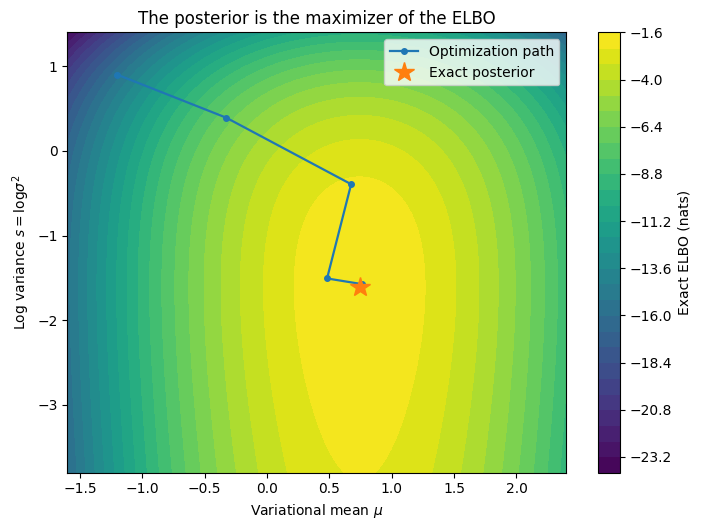

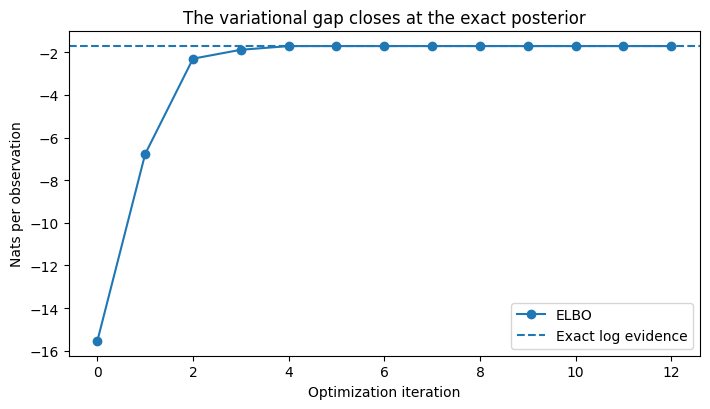

In [3]:
path = []
def objective(par):
    mu, s = par
    value = -scalar_elbo(mu, s)
    grad_mu = -(a*(d-a*mu)/(tau*tau) - mu)
    grad_s = 0.5 * (np.exp(s)*(a*a/(tau*tau)+1)-1)
    return value, np.array([grad_mu, grad_s])

start = np.array([-1.2, 0.9])
path.append(start.copy())
solution = optimize.minimize(objective, start, jac=True, method="BFGS",
                             callback=lambda p: path.append(p.copy()),
                             options={"gtol": 1e-10})
path = np.asarray(path)
np.testing.assert_allclose(solution.x, [m_post, np.log(v_post)], atol=1e-7)

mu_axis = np.linspace(-1.6, 2.4, 220)
s_axis = np.linspace(-3.8, 1.4, 220)
mu_grid, s_grid = np.meshgrid(mu_axis, s_axis)
plt.figure(figsize=(7.2, 5.4))
contours = plt.contourf(mu_grid, s_grid, scalar_elbo(mu_grid, s_grid), levels=28)
plt.colorbar(contours, label="Exact ELBO (nats)")
plt.plot(path[:, 0], path[:, 1], "o-", label="Optimization path", linewidth=1.6, markersize=4)
plt.plot(m_post, np.log(v_post), "*", markersize=15, label="Exact posterior")
plt.xlabel(r"Variational mean $\mu$")
plt.ylabel(r"Log variance $s=\log\sigma^2$")
plt.title("The posterior is the maximizer of the ELBO")
plt.legend()
show_figure("01_elbo_landscape")

plt.figure(figsize=(7.2, 4.2))
plt.plot(scalar_elbo(path[:, 0], path[:, 1]), "o-", label="ELBO")
plt.axhline(log_evidence, linestyle="--", label="Exact log evidence")
plt.xlabel("Optimization iteration")
plt.ylabel("Nats per observation")
plt.title("The variational gap closes at the exact posterior")
plt.legend()
show_figure("02_elbo_gap")

## 2. What a diagonal variational family excludes

The Gaussian encoder of [KW, Eq. (9)] is a modeling choice, not a theorem about the true posterior. Consider a normalized target $p_*=\mathcal N(0,\Sigma)$, with
$$\Sigma=\begin{pmatrix}1&\rho\\\rho&1\end{pmatrix},\quad |\rho|<1,$$
and approximate it by $q=\mathcal N(\mu,V)$, $V=\operatorname{diag}(v_1,v_2)$, $v_j>0$.
Expanding the two Gaussian log densities and using
$\mathbb E_q[z^\mathsf T\Sigma^{-1}z]
=\operatorname{tr}(\Sigma^{-1}V)+\mu^\mathsf T\Sigma^{-1}\mu$ gives
$$D_{\rm KL}(q\|p_*)=\frac12\left[
\operatorname{tr}(\Sigma^{-1}V)+\mu^\mathsf T\Sigma^{-1}\mu-2+
\log\frac{\det\Sigma}{\det V}\right].$$
Differentiation gives $\mu_*=0$ and $v_j=1/(\Sigma^{-1})_{jj}=1-\rho^2$.
Consequently, the minimum KL is $-\tfrac12\log(1-\rho^2)>0$ when $\rho\ne0$.
The optimal variational marginal variances are smaller than the target variances in this example.
More accurate stochastic gradients cannot remove this family restriction.

The contours show equal Mahalanobis radii, not equal density heights. Solid contours describe the target; dashed contours describe its optimal diagonal approximation.

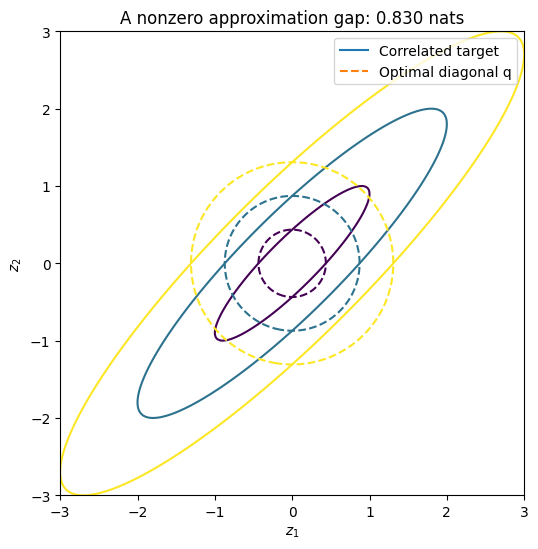

In [4]:
rho = 0.9
Sigma = np.array([[1.0, rho], [rho, 1.0]])
precision = np.linalg.inv(Sigma)
V_diag = np.diag(1.0 / np.diag(precision))
min_kl = 0.5 * (np.trace(precision @ V_diag)-2 +
                np.linalg.slogdet(Sigma)[1]-np.linalg.slogdet(V_diag)[1])
np.testing.assert_allclose(min_kl, -0.5*np.log1p(-rho*rho), atol=1e-12)
results["mean_field"] = {"rho": rho, "variance": 1-rho*rho, "minimum_kl": min_kl}

u = np.linspace(-3, 3, 250)
u1, u2 = np.meshgrid(u, u)
points = np.stack([u1, u2], axis=-1)
r_target = np.einsum("...i,ij,...j->...", points, precision, points)
r_diagonal = np.einsum("...i,ij,...j->...", points, np.linalg.inv(V_diag), points)
plt.figure(figsize=(6.4, 5.6))
plt.contour(u1, u2, r_target, levels=[1, 4, 9], linestyles="solid")
plt.contour(u1, u2, r_diagonal, levels=[1, 4, 9], linestyles="dashed")
plt.plot([], [], linestyle="solid", label="Correlated target")
plt.plot([], [], linestyle="dashed", label="Optimal diagonal q")
plt.gca().set_aspect("equal")
plt.xlabel(r"$z_1$")
plt.ylabel(r"$z_2$")
plt.title(f"A nonzero approximation gap: {min_kl:.3f} nats")
plt.legend()
show_figure("03_mean_field")

## 3. Differentiating an expectation

Let $F(\phi)=\int q_\phi(z)f_\phi(z)\,dz$. Assume a parameter-independent support and an integrable dominating function for the derivative locally in $\phi$. The product rule gives the score-function identity
$$\nabla_\phi F
=\mathbb E_{q_\phi}\left[\nabla_\phi f_\phi(z)+f_\phi(z)\nabla_\phi\log q_\phi(z)\right].$$
The first term must not be omitted when the integrand depends explicitly on $\phi$.
Since $\mathbb E_q\nabla_\phi\log q_\phi=\nabla_\phi\int q_\phi=0$, a baseline independent of $z$ may be subtracted from the score multiplier.

Alternatively, suppose $z=g_\phi(\epsilon,x)$ pushes a fixed noise law $p(\epsilon)$ to $q_\phi(z\mid x)$. Then
$$F(\phi)=\mathbb E_{p(\epsilon)}f_\phi(g_\phi(\epsilon,x)),$$
and, under an integrable domination condition for the total derivative,
$$\nabla_\phi F=\mathbb E_{p(\epsilon)}\left[
\left.\nabla_\phi f_\phi(z)\right|_{z=g_\phi}
+(\partial_\phi g_\phi)^\mathsf T\nabla_z f_\phi(g_\phi)\right].$$
This is the pathwise derivative underlying SGVB [KW, Eqs. (4)–(7)]. Differentiability almost everywhere alone does not justify interchanging a derivative and an integral.

### A variance calculation with a known answer

Take $z=\mu+\sigma\epsilon$, $\epsilon\sim\mathcal N(0,1)$, $\sigma>0$, and $f(z)=(z-c)^2$, with $c$ fixed. Put $\delta=\mu-c$. Then
$F=\delta^2+\sigma^2$ and $\partial_\mu F=2\delta$.
The two single-sample estimators are
$$G_{\rm path}=2(\delta+\sigma\epsilon),\qquad
G_{\rm score}=(\delta+\sigma\epsilon)^2\epsilon/\sigma.$$
Gaussian integration by parts gives $\mathbb E\epsilon^{2r}=(2r-1)\mathbb E\epsilon^{2r-2}$ and odd moments zero. Expanding the polynomials therefore gives
$$\operatorname{Var}G_{\rm path}=4\sigma^2,\quad
\operatorname{Var}G_{\rm score}=\delta^4/\sigma^2+14\delta^2+15\sigma^2.$$
For the baseline $b=F$, the score variance is $8\delta^2+10\sigma^2$.
An average of $L$ independent estimates has variance divided by $L$.
These formulas establish a comparison for this particular example, not a universal ordering of all gradient estimators.

,estimator,L,mean,empirical_sd,theoretical_sd
0,Pathwise,1,-3.1851,1.3981,1.4000
1,Score,1,-3.1359,7.4831,7.5210
2,Score + baseline,1,-3.1825,5.0232,5.0379
3,Pathwise,4,-3.2022,0.6988,0.7000
4,Score,4,-3.1799,3.7366,3.7605
5,Score + baseline,4,-3.1730,2.4937,2.5189
6,Pathwise,16,-3.1966,0.3481,0.3500
7,Score,16,-3.1987,1.8783,1.8802
8,Score + baseline,16,-3.2093,1.2678,1.2595
9,Pathwise,64,-3.2007,0.1750,0.1750


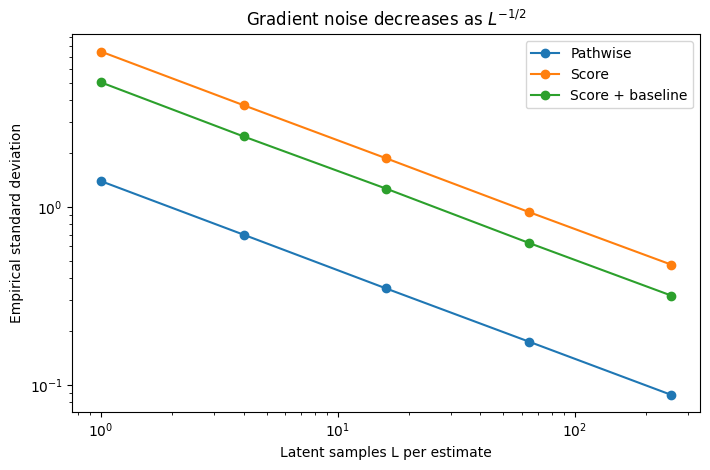

In [5]:
mu0, sigma0, c0 = 0.4, 0.7, 2.0
delta = mu0-c0
truth = 2*delta
sample_sizes = np.array([1, 4, 16, 64, 256])
repetitions = 12000
rng = np.random.default_rng(SEED+1)
variances = {
    "Pathwise": 4*sigma0**2,
    "Score": delta**4/sigma0**2 + 14*delta**2 + 15*sigma0**2,
    "Score + baseline": 8*delta**2 + 10*sigma0**2,
}
records = []
for L in sample_sizes:
    eps = rng.normal(size=(repetitions, int(L)))
    z_minus_c = delta + sigma0*eps
    estimators = {
        "Pathwise": 2*z_minus_c,
        "Score": z_minus_c**2 * eps/sigma0,
        "Score + baseline": (z_minus_c**2-(delta**2+sigma0**2))*eps/sigma0,
    }
    for name, draws in estimators.items():
        means = draws.mean(axis=1)
        records.append({"estimator": name, "L": int(L), "mean": means.mean(),
                        "empirical_sd": means.std(ddof=1),
                        "theoretical_sd": np.sqrt(variances[name]/L)})
gradient_table = pd.DataFrame(records)
results["gradient"] = {"exact_mean": truth, "single_sample_variances": variances}
display(gradient_table.round(4))

plt.figure(figsize=(7.2, 4.8))
for name, group in gradient_table.groupby("estimator", sort=False):
    plt.loglog(group.L, group.empirical_sd, "o-", label=name)
plt.xlabel("Latent samples L per estimate")
plt.ylabel("Empirical standard deviation")
plt.title("Gradient noise decreases as $L^{-1/2}$")
plt.legend()
show_figure("04_gradient_variance")

### Sampling and automatic differentiation

For a Gaussian encoder, $s=\log\sigma^2$ and
$$z=\mu+\exp(s/2)\odot\epsilon,$$
where $\odot$ is the coordinatewise product. The factor $1/2$ is essential: `exp(logvar)` is the variance, not the standard deviation.

`Normal.rsample()` preserves the pathwise derivative; `Normal.sample()` does not [PyTorch distribution documentation]. The next cell also checks a derivative by centered finite differences, holding the noise fixed. Resampling on each side of the finite difference would test Monte Carlo noise as well as differentiation.

In [6]:
# This small finite-difference check is deliberately evaluated on CPU.
mu_t = torch.tensor(0.4, dtype=torch.float64, device="cpu", requires_grad=True)
s_t = torch.tensor(np.log(0.7**2), dtype=torch.float64, device="cpu", requires_grad=True)
gen = torch.Generator(device="cpu").manual_seed(SEED+2)
eps_fixed = torch.randn(4096, generator=gen, dtype=torch.float64, device="cpu")

def mc_function(mu, s):
    z = mu + torch.exp(s/2)*eps_fixed
    return ((z-c0)**2).mean()

value = mc_function(mu_t, s_t)
g_mu, g_s = torch.autograd.grad(value, (mu_t, s_t))
h = 1e-5
fd_mu = (mc_function(mu_t.detach()+h, s_t.detach())-
         mc_function(mu_t.detach()-h, s_t.detach()))/(2*h)
fd_s = (mc_function(mu_t.detach(), s_t.detach()+h)-
        mc_function(mu_t.detach(), s_t.detach()-h))/(2*h)
np.testing.assert_allclose([g_mu.item(), g_s.item()],
                           [fd_mu.item(), fd_s.item()], rtol=1e-8, atol=1e-8)
dist = torch.distributions.Normal(mu_t, torch.exp(s_t/2))
assert dist.rsample().requires_grad
assert not dist.sample().requires_grad
print("Pathwise finite-difference check passed; sample()/rsample() distinction verified.")

Pathwise finite-difference check passed; sample()/rsample() distinction verified.


## 4. From SGVB to a Bernoulli VAE

Use the prior and approximate posterior of [KW, Section 3]:
$$p_\theta(z)=\mathcal N(0,I_J),\quad
q_\phi(z\mid x)=\mathcal N\!\left(\mu_\phi(x),\operatorname{diag}(\sigma_\phi^2(x))\right).$$
The prior has no trainable parameters in this example. The paper writes a vector of variances times $I$; `diag` makes the intended diagonal matrix explicit.

For each coordinate, $\mathbb E_q z_j^2=\mu_j^2+\sigma_j^2$ and
$\mathbb E_q(z_j-\mu_j)^2/\sigma_j^2=1$. Hence
$$\begin{aligned}
\mathbb E_q\log p(z)&=-\frac J2\log(2\pi)-\frac12\sum_j(\mu_j^2+\sigma_j^2),\\
\mathbb E_q\log q(z\mid x)&=-\frac J2\log(2\pi)-\frac12\sum_j(1+\log\sigma_j^2).
\end{aligned}$$
Subtracting yields [KW, Appendix B]
$$\boxed{D_{\rm KL}(q\|p)=\frac12\sum_{j=1}^J
\left[\mu_j^2+e^{s_j}-1-s_j\right].}$$
In particular $\partial_{\mu_j}D_{\rm KL}=\mu_j$ and
$\partial_{s_j}D_{\rm KL}=\tfrac12(e^{s_j}-1)$.

In [7]:
def kl_standard_normal(mu: torch.Tensor, logvar: torch.Tensor) -> torch.Tensor:
    """KL(N(mu, diag(exp(logvar))) || N(0, I)), summed over the last axis."""
    if mu.shape != logvar.shape:
        raise ValueError("mu and logvar must have the same shape")
    return 0.5 * (mu.square() + logvar.exp() - 1.0 - logvar).sum(dim=-1)

# Compare the formula with the distribution library, including its gradient.
check_mu = torch.tensor([[0.2, -0.5], [0.0, 0.7]], dtype=torch.float64, device="cpu", requires_grad=True)
check_s = torch.tensor([[-1.0, 0.3], [0.5, -0.7]], dtype=torch.float64, device="cpu", requires_grad=True)
q_check = torch.distributions.Independent(
    torch.distributions.Normal(check_mu, torch.exp(check_s/2)), 1)
p_check = torch.distributions.Independent(
    torch.distributions.Normal(torch.zeros_like(check_mu), torch.ones_like(check_mu)), 1)
manual = kl_standard_normal(check_mu, check_s)
reference = torch.distributions.kl_divergence(q_check, p_check)
assert torch.allclose(manual, reference, atol=1e-12)
d_mu, d_s = torch.autograd.grad(manual.sum(), (check_mu, check_s))
assert torch.allclose(d_mu, check_mu)
assert torch.allclose(d_s, 0.5*(check_s.exp()-1))
assert torch.all(kl_standard_normal(torch.zeros(4, 3, device="cpu"), torch.zeros(4, 3, device="cpu")) == 0)
print("Gaussian KL values, gradients, and zero-KL case verified.")

Gaussian KL values, gradients, and zero-KL case verified.


### Observation model, data support, and network outputs

For $x\in\{0,1\}^D$, conditional independence defines
$$p_\theta(x\mid z)=\prod_{d=1}^D
\rho_{\theta,d}(z)^{x_d}[1-\rho_{\theta,d}(z)]^{1-x_d}.$$
Let $a_\theta(z)\in\mathbb R^D$ be decoder logits and
$\rho_{\theta,d}=1/(1+e^{-a_{\theta,d}})$. Taking logarithms and using
$-\log\rho=\operatorname{softplus}(-a)$ gives
$$-\log p_\theta(x\mid z)=\sum_{d=1}^D
[\operatorname{softplus}(a_{\theta,d})-x_d a_{\theta,d}].$$
This is a **sum** of binary cross-entropies. Dividing it by $D$ while leaving KL unchanged would alter the objective.
The symbol $y$ in [KW, Appendix C.1] denotes decoder probabilities; here it is renamed $\rho_\theta$ so that $y$ can later denote a supervised target.

The original digits have integer intensities $r_d\in\{0,\ldots,16\}$. We define the modeled observation as $x_d=\mathbf1\{r_d\geq8\}$. This explicit binarization gives a valid Bernoulli likelihood; evaluating a Bernoulli mass function on arbitrary grayscale values would not.

The encoder and decoder each have one tanh hidden layer of width $H=128$, as in the MLP construction of [KW, Appendix C], with smaller dimensions. The encoder maps $\mathbb R^D$ to $\mu,s\in\mathbb R^J$; the decoder maps $\mathbb R^J$ to $D$ logits. The two experiments use $J=2$ and $J=8$. Labels are excluded from VAE training and checkpoint selection.

In [8]:
digits = load_digits()
X_digits = (digits.data >= 8).astype(np.float32)
y_digits = digits.target.astype(np.int64) + 1  # Formal labels 1,...,K; glyph = y-1.
all_indices = np.arange(len(X_digits))
idx_trainval, idx_test = train_test_split(
    all_indices, test_size=360, stratify=y_digits, random_state=SEED)
idx_train, idx_val = train_test_split(
    idx_trainval, test_size=360, stratify=y_digits[idx_trainval], random_state=SEED+1)
x_train, x_val, x_test = [tensor(X_digits[idx]) for idx in (idx_train, idx_val, idx_test)]
assert set(idx_train).isdisjoint(idx_val) and set(idx_train).isdisjoint(idx_test)
assert set(idx_val).isdisjoint(idx_test)
assert torch.all((x_train == 0) | (x_train == 1))
D = x_train.shape[1]
results["digits_data"] = {
    "name": "UCI 8x8 digits via sklearn.load_digits", "binarization": "intensity >= 8",
    "D": D, "N_train": len(idx_train), "N_val": len(idx_val), "N_test": len(idx_test),
    "data_sha256": hashlib.sha256(X_digits.tobytes()+y_digits.tobytes()).hexdigest(),
}
display(pd.Series(results["digits_data"], name="Protocol").to_frame())

class BernoulliVAE(nn.Module):
    def __init__(self, observed_dim: int, latent_dim: int, hidden_dim: int = 128):
        super().__init__()
        self.observed_dim, self.latent_dim = observed_dim, latent_dim
        self.encoder_hidden = nn.Linear(observed_dim, hidden_dim)
        self.encoder_mu = nn.Linear(hidden_dim, latent_dim)
        self.encoder_logvar = nn.Linear(hidden_dim, latent_dim)
        self.decoder_hidden = nn.Linear(latent_dim, hidden_dim)
        self.decoder_logits = nn.Linear(hidden_dim, observed_dim)

    def encode(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        h = torch.tanh(self.encoder_hidden(x))
        return self.encoder_mu(h), self.encoder_logvar(h)

    def decode(self, z: torch.Tensor) -> torch.Tensor:
        return self.decoder_logits(torch.tanh(self.decoder_hidden(z)))

    def terms(self, x: torch.Tensor, eps: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        # x: (M,D), eps: (L,M,J), logits: (L,M,D).
        mu, logvar = self.encode(x)
        z = mu.unsqueeze(0) + torch.exp(logvar.unsqueeze(0)/2)*eps
        logits = self.decode(z)
        expanded_x = x.unsqueeze(0).expand_as(logits)
        nll = F.binary_cross_entropy_with_logits(logits, expanded_x, reduction="none").sum(-1)
        kl = kl_standard_normal(mu, logvar)
        return nll.mean(0), kl  # Each has shape (M,).

,Protocol
name,UCI 8x8 digits via sklearn.load_digits
binarization,intensity >= 8
D,64
N_train,1077
N_val,360
N_test,360
data_sha256,541c97607e3c10fb3f113fe0130b2d1e80ec16fbfe55c9...


### The minibatch objective

With $z^{(i,l)}=\mu^{(i)}+\sigma^{(i)}\odot\epsilon^{(i,l)}$,
$$\widetilde{\mathcal L}^{B}(\theta,\phi;x^{(i)})
=\frac1L\sum_{l=1}^L\log p_\theta(x^{(i)}\mid z^{(i,l)})-
D_{\rm KL}(q_\phi(z\mid x^{(i)})\|p(z)).\tag{KW.7}$$
Its expectation is the exact ELBO. An individual random value need not be below $\log p_\theta(x^{(i)})$.
If $i_1,\ldots,i_M$ are sampled uniformly and independently from $\{1,\ldots,N\}$, then
$$\mathbb E\left[\frac NM\sum_{m=1}^M\widetilde{\mathcal L}^{B}(x^{(i_m)})\right]
=\sum_{i=1}^{N}\mathcal L(x^{(i)}).\tag{KW.8}$$
The code minimizes the negative **average** ELBO, so it uses $M^{-1}$ rather than $N/M$.
Uniform sampling with replacement makes this estimator conditionally unbiased at each update.
An “epoch” below is $\lceil N/M\rceil$ such updates, not a traversal of a shuffled dataset.

Training uses $M=100$, $L=1$, Adam with learning rate $10^{-3}$, and **no** KL warm-up, extra KL coefficient, or weight decay. [KW] used Adagrad and a parameter prior in its reported experiments. Thus this implementation optimizes an approximate ML criterion, not that paper's MAP criterion.

Validation uses $L=16$ and fixed noise, only for checkpoint selection. Test evaluation uses fresh, independent noise and $L=128$. Averages of training losses during an epoch involve changing parameters; the plotted training curves instead evaluate a fixed checkpoint at the end of each epoch.

In [9]:
@torch.no_grad()
def evaluate_vae(model: BernoulliVAE, x: torch.Tensor, L: int, seed: int) -> dict:
    model.eval()
    gen = torch.Generator(device=x.device).manual_seed(seed)
    nll_parts, kl_parts = [], []
    for batch in x.split(128):
        eps = torch.randn(L, len(batch), model.latent_dim,
                          generator=gen, device=batch.device, dtype=batch.dtype)
        nll, kl = model.terms(batch, eps)
        nll_parts.append(nll)
        kl_parts.append(kl)
    nll, kl = torch.cat(nll_parts), torch.cat(kl_parts)
    per_point = nll+kl
    return {"negative_elbo": per_point.mean().item(), "reconstruction_nll": nll.mean().item(),
            "kl": kl.mean().item(), "observation_se": per_point.std().item()/math.sqrt(len(x))}

def train_vae(latent_dim: int, epochs: int = 260) -> tuple[BernoulliVAE, list, int]:
    seed = SEED + 100 + latent_dim
    torch.manual_seed(seed)
    model = BernoulliVAE(D, latent_dim).to(DEVICE)
    path = CKPT_DIR / f"digits_vae_J{latent_dim}.pt"
    if not TRAIN:
        if not path.exists():
            raise FileNotFoundError(f"{path} is missing. Set TRAIN=True or unpack the complete bundle.")
        saved = torch.load(path, map_location=next(model.parameters()).device, weights_only=True)
        model.load_state_dict(saved["state_dict"])
        model.eval()
        return model, saved["history"], saved["best_epoch"]
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    gen = torch.Generator(device=x_train.device).manual_seed(seed+1)
    history, best_value, best_state, best_epoch = [], np.inf, None, -1
    for epoch in range(1, epochs+1):
        model.train()
        for _ in range(math.ceil(len(x_train)/100)):
            indices = torch.randint(len(x_train), (100,), generator=gen, device=x_train.device)
            batch = x_train[indices]
            eps = torch.randn(1, len(batch), latent_dim,
                              generator=gen, device=batch.device, dtype=batch.dtype)
            nll, kl = model.terms(batch, eps)
            loss = (nll+kl).mean()
            if not torch.isfinite(loss):
                raise FloatingPointError("Nonfinite VAE objective")
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
        val = evaluate_vae(model, x_val, L=16, seed=SEED+300)
        train_eval = evaluate_vae(model, x_train[:512], L=4, seed=SEED+301)
        history.append({"epoch": epoch, "train": train_eval["negative_elbo"],
                        "validation": val["negative_elbo"], "kl": val["kl"],
                        "reconstruction": val["reconstruction_nll"]})
        if val["negative_elbo"] < best_value:
            best_value, best_epoch = val["negative_elbo"], epoch
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    model.eval()
    torch.save({"state_dict": {name: value.detach().cpu() for name, value in best_state.items()}, "history": history, "best_epoch": best_epoch}, path)
    return model, history, best_epoch

vae2, history2, best2 = train_vae(2)
vae8, history8, best8 = train_vae(8)
vae_metrics = []
for model, best_epoch in [(vae2, best2), (vae8, best8)]:
    metrics = evaluate_vae(model, x_test, L=128, seed=SEED+302)
    metrics.update(J=model.latent_dim, best_epoch=best_epoch)
    vae_metrics.append(metrics)
results["vae"] = vae_metrics
display(pd.DataFrame(vae_metrics).set_index("J").round(4))
print("observation_se describes variation across held-out observations, not only Monte Carlo noise.")

,negative_elbo,reconstruction_nll,kl,observation_se,best_epoch
J,,,,,
2,20.1339,17.2945,2.8394,0.2586,260
8,18.3982,12.3618,6.0364,0.1981,260


observation_se describes variation across held-out observations, not only Monte Carlo noise.


### Learning curves

The negative ELBO is the sum of reconstruction NLL and prior KL. Smaller values are better in the following plot. Curves from different latent dimensions use the same data and likelihood, so they have the same units. They are single-seed teaching runs, not a statistically controlled benchmark.

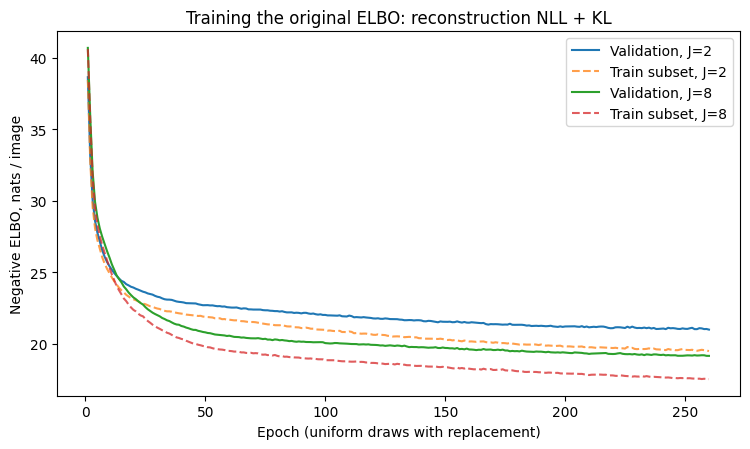

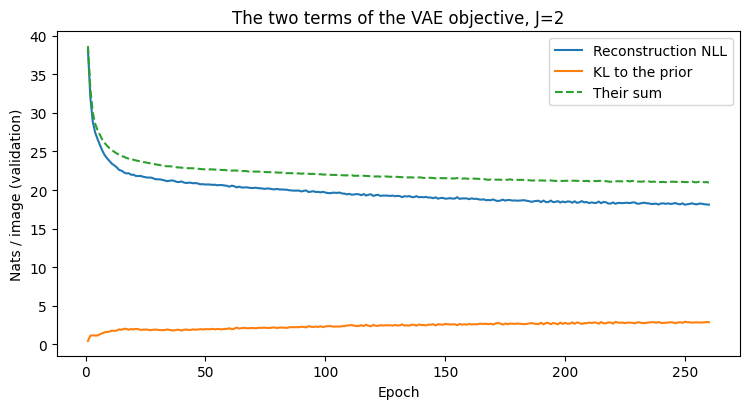

In [10]:
plt.figure(figsize=(7.6, 4.6))
for J, history in [(2, history2), (8, history8)]:
    frame = pd.DataFrame(history)
    plt.plot(frame.epoch, frame.validation, label=f"Validation, J={J}")
    plt.plot(frame.epoch, frame.train, linestyle="--", alpha=0.75, label=f"Train subset, J={J}")
plt.xlabel("Epoch (uniform draws with replacement)")
plt.ylabel("Negative ELBO, nats / image")
plt.title("Training the original ELBO: reconstruction NLL + KL")
plt.legend()
show_figure("05_vae_learning")

plt.figure(figsize=(7.6, 4.2))
frame = pd.DataFrame(history2)
plt.plot(frame.epoch, frame.reconstruction, label="Reconstruction NLL")
plt.plot(frame.epoch, frame.kl, label="KL to the prior")
plt.plot(frame.epoch, frame.validation, linestyle="--", label="Their sum")
plt.xlabel("Epoch")
plt.ylabel("Nats / image (validation)")
plt.title("The two terms of the VAE objective, J=2")
plt.legend()
show_figure("06_vae_terms")

## 5. Reconstructions, latent coordinates, and generation

These operations answer different questions. Given an observed $x$, the encoder approximates $p_\theta(z\mid x)$. A commonly displayed reconstruction is $\rho_\theta(\mu_\phi(x))$; it is neither a random image nor generally equal to $\mathbb E_q\rho_\theta(z)$, because the decoder is nonlinear. The next mosaic compares those quantities.

Unconditional generation instead draws $z\sim p(z)$ and then $x\sim p_\theta(x\mid z)$. Decoder probabilities are conditional means, not sampled binary observations. The following cells label these two displays separately.

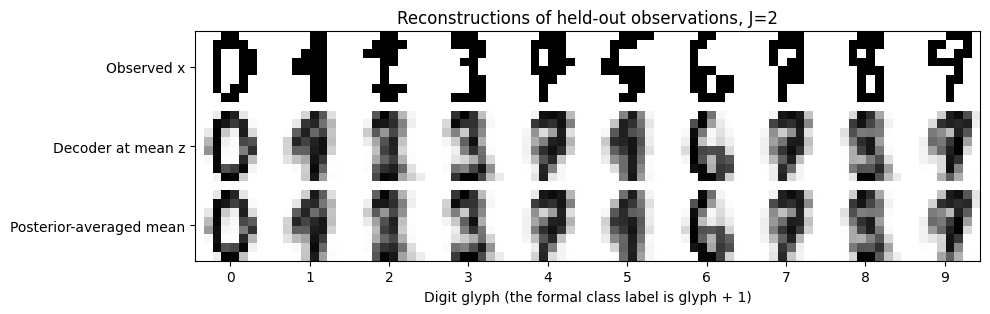

In [11]:
def mosaic(images: np.ndarray, rows: int, cols: int, gap: int = 1) -> np.ndarray:
    """Tile scalar images into one array, without creating a grid of axes."""
    images = np.asarray(images).reshape(-1, 8, 8)
    if len(images) != rows*cols:
        raise ValueError("The image count must equal rows*cols")
    canvas = np.zeros((rows*8+(rows-1)*gap, cols*8+(cols-1)*gap), dtype=float)
    for k, image in enumerate(images):
        r, c = divmod(k, cols)
        canvas[r*(8+gap):r*(8+gap)+8, c*(8+gap):c*(8+gap)+8] = image
    return canvas

# One held-out image of each digit, chosen by order rather than reconstruction quality.
chosen = np.array([np.flatnonzero(y_digits[idx_test] == k+1)[0] for k in range(10)])
originals = x_test[torch.as_tensor(chosen, dtype=torch.long, device=x_test.device)]
with torch.no_grad():
    mu, logvar = vae2.encode(originals)
    deterministic = vae2.decode(mu).sigmoid()
    gen = torch.Generator(device=mu.device).manual_seed(SEED+400)
    eps = torch.randn(256, len(originals), vae2.latent_dim,
                      generator=gen, device=mu.device, dtype=mu.dtype)
    z = mu[None] + torch.exp(logvar[None]/2)*eps
    averaged = vae2.decode(z).sigmoid().mean(0)
images = torch.cat([originals, deterministic, averaged]).detach().cpu().numpy()
plt.figure(figsize=(10, 3.9))
plt.imshow(mosaic(images, 3, 10), cmap="gray_r", interpolation="nearest", vmin=0, vmax=1)
plt.xticks(np.arange(10)*9+3.5, np.arange(10))
plt.yticks(np.arange(3)*9+3.5, ["Observed x", "Decoder at mean z", "Posterior-averaged mean"])
plt.title("Reconstructions of held-out observations, J=2")
plt.xlabel("Digit glyph (the formal class label is glyph + 1)")
show_figure("07_reconstructions")

### Two-dimensional encoding

The coordinates in this plot are $\mu_\phi(x)$ for held-out observations. Labels are used **only after fitting**, to annotate the plot. A visually separated cloud is not a classification objective or evidence of class-calibrated probabilities. The generative model does not uniquely identify the semantic meaning of a latent axis.

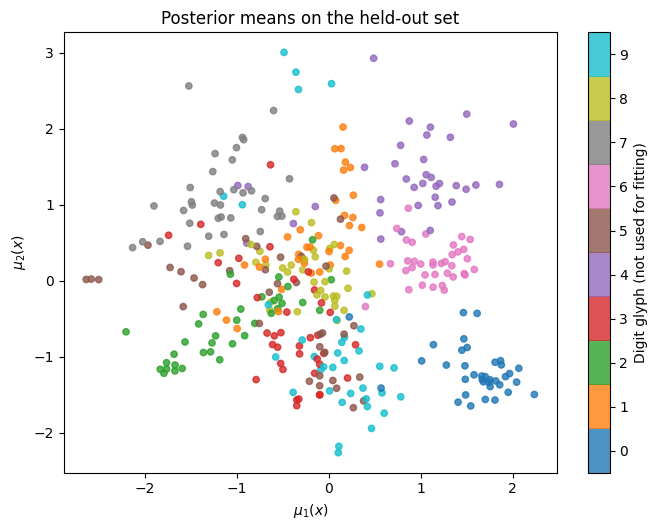

In [12]:
with torch.no_grad():
    latent_mu, latent_logvar = vae2.encode(x_test)
plt.figure(figsize=(7.0, 5.4))
points_plot = plt.scatter(latent_mu[:, 0].detach().cpu().numpy(),
                         latent_mu[:, 1].detach().cpu().numpy(), c=y_digits[idx_test]-1,
                         s=21, alpha=0.8, vmin=-0.5, vmax=9.5, cmap="tab10")
plt.colorbar(points_plot, ticks=np.arange(10), label="Digit glyph (not used for fitting)")
plt.xlabel(r"$\mu_1(x)$")
plt.ylabel(r"$\mu_2(x)$")
plt.title("Posterior means on the held-out set")
show_figure("08_latent_codes")

### A decoder grid in prior quantiles

To cover the Gaussian prior more evenly than a uniform grid in $z$, choose evenly spaced $u\in[0.03,0.97]$ and set $z_j=\Phi^{-1}(u_j)$, where $\Phi$ is the standard normal CDF. This is the visualization rule used in [KW, Appendix A, Figure 4]. Every tile below is the conditional mean $\rho_\theta(z)$, not a draw from $p_\theta(x\mid z)$.

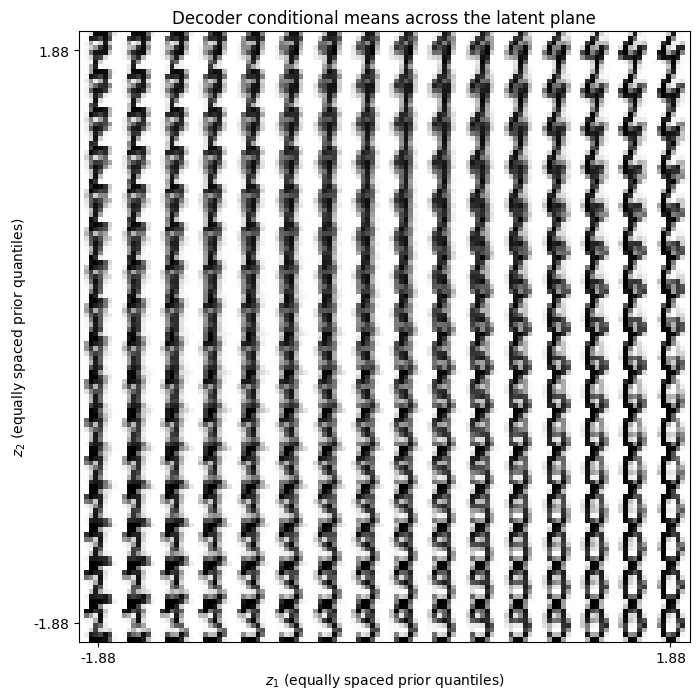

In [13]:
quantiles = stats.norm.ppf(np.linspace(0.03, 0.97, 16))
z1, z2 = np.meshgrid(quantiles, quantiles[::-1])
grid_z = tensor(np.stack([z1.ravel(), z2.ravel()], axis=1))
with torch.no_grad():
    grid_means = vae2.decode(grid_z).sigmoid().detach().cpu().numpy()
plt.figure(figsize=(7.1, 7.1))
plt.imshow(mosaic(grid_means, 16, 16, gap=0), cmap="gray_r", interpolation="nearest")
plt.xticks([3.5, 123.5], [f"{quantiles[0]:.2f}", f"{quantiles[-1]:.2f}"])
plt.yticks([3.5, 123.5], [f"{quantiles[-1]:.2f}", f"{quantiles[0]:.2f}"])
plt.xlabel(r"$z_1$ (equally spaced prior quantiles)")
plt.ylabel(r"$z_2$ (equally spaced prior quantiles)")
plt.title("Decoder conditional means across the latent plane")
show_figure("09_latent_manifold")

### Prior samples: means versus observations

For each sampled latent vector, the first mosaic displays the conditional mean. The second draws independent Bernoulli coordinates using the same probabilities. The difference is observation noise, not uncertainty about the fitted weights.

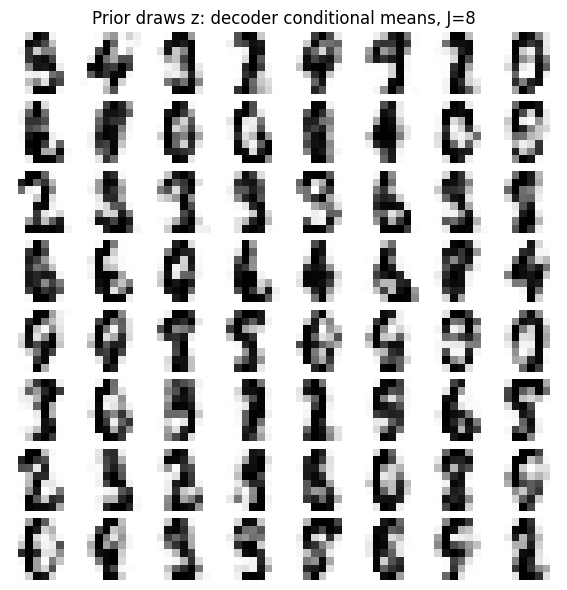

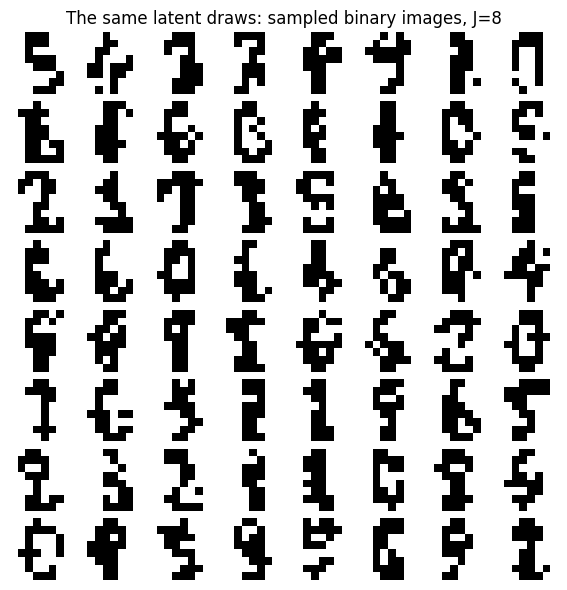

In [14]:
with torch.no_grad():
    model_parameter = next(vae8.parameters())
    gen = torch.Generator(device=model_parameter.device).manual_seed(SEED+401)
    prior_z = torch.randn(64, vae8.latent_dim, generator=gen,
                          device=model_parameter.device, dtype=model_parameter.dtype)
    prior_means = vae8.decode(prior_z).sigmoid()
    prior_samples = torch.bernoulli(prior_means, generator=gen)
for name, image_values, title in [
    ("10_prior_means", prior_means, "Prior draws z: decoder conditional means, J=8"),
    ("11_prior_samples", prior_samples, "The same latent draws: sampled binary images, J=8"),
]:
    plt.figure(figsize=(6.0, 6.0))
    plt.imshow(mosaic(image_values.detach().cpu().numpy(), 8, 8), cmap="gray_r", interpolation="nearest")
    plt.axis("off")
    plt.title(title)
    show_figure(name)

### Evidence estimation is a separate calculation

For a proposal $q_\phi(z\mid x)$ covering the support of $p_\theta(x,z)$, define
$$w(z)=\frac{p_\theta(x,z)}{q_\phi(z\mid x)}.$$
Then $\mathbb E_qw=\int p_\theta(x,z)dz=p_\theta(x)$, whereas
$\mathbb E_q\log w=\mathcal L$. For $S$ independent proposal draws,
$$\widehat p_S(x)=S^{-1}\sum_s w_s,\qquad
\log\widehat p_S(x)=\operatorname{logsumexp}_s(\log w_s)-\log S.$$
The density estimate is unbiased; its logarithm generally is not. Jensen gives
$\mathbb E\log\widehat p_S\leq\log p_\theta(x)$, but **one realized estimate is not a guaranteed lower bound**. For the same realized log weights, their log-mean-exp is at least their mean, again by Jensen.

The diagnostic $\mathrm{ESS}=(\sum_s w_s)^2/\sum_s w_s^2$ is the inverse sum of squared normalized weights. It measures weight concentration, not a certified error bar. This elementary importance sampler is a teaching extension, **not** the MCMC estimator in [KW, Appendix D].

In [15]:
@torch.no_grad()
def importance_diagnostic(model: BernoulliVAE, x: torch.Tensor, S: int = 256) -> pd.DataFrame:
    gen = torch.Generator(device=x.device).manual_seed(SEED+402)
    mu, logvar = model.encode(x)
    eps = torch.randn(S, len(x), model.latent_dim,
                      generator=gen, device=mu.device, dtype=mu.dtype)
    z = mu[None] + torch.exp(logvar[None]/2)*eps
    logits = model.decode(z)
    log_px = -F.binary_cross_entropy_with_logits(
        logits, x[None].expand_as(logits), reduction="none").sum(-1)
    log_pz = -0.5*(z.square()+math.log(2*math.pi)).sum(-1)
    log_qz = -0.5*(eps.square()+logvar[None]+math.log(2*math.pi)).sum(-1)
    log_w = (log_px+log_pz-log_qz).double()
    log_mean_w = torch.logsumexp(log_w, dim=0)-math.log(S)
    mean_log_w = log_w.mean(0)
    norm_w = torch.softmax(log_w, dim=0)
    ess = 1/norm_w.square().sum(0)
    assert torch.all(log_mean_w >= mean_log_w-1e-10)
    return pd.DataFrame({"MC_ELBO_A": mean_log_w.detach().cpu().numpy(),
                         "log_mean_weight": log_mean_w.detach().cpu().numpy(), "ESS": ess.detach().cpu().numpy()})

importance_table = importance_diagnostic(vae8, x_test[:128])
results["importance"] = {"N_test_used": 128, "S": 256,
                          **{k: float(v) for k, v in importance_table.mean().items()}}
display(importance_table.agg(["mean", "median", "min", "max"]).round(3))

,MC_ELBO_A,log_mean_weight,ESS
mean,-18.573,-17.985,90.289
median,-18.142,-17.613,92.811
min,-27.623,-26.740,5.576
max,-9.530,-9.111,159.964


## 6. The supervised notation $(x,y)$

Now let $\mathcal D=\{(x_i,y_i)\}_{i=1}^N$, with $x_i\in\mathbb R^n$.
For classification, $y_i\in\{1,\ldots,K\}$; for regression, $y_i\in\mathbb R$.
There are three distinct uses of the VAE idea.

**Representation followed by prediction.** Keep the original observed variable $x$ and fit the VAE without labels. Freeze its encoder and fit a separate predictor $r_\psi(y\mid\mu_\phi(x))$. This predictor has new parameters $\psi$ and a supervised objective; it is not an output distribution already defined by the original VAE.

**Joint modeling.** Regard $\widetilde x=(x,y)$ as the observation in (KW.1). Define
$$p_\theta(x,y,z)=p_\theta(z)p_\theta(x\mid z)p_\theta(y\mid x,z),$$
with an appropriate categorical mass or real-valued density for the target. Inserting this factorization into (KW.3) gives
$$\mathcal L_{\rm joint}
=\mathbb E_{q_\phi(z\mid x,y)}[\log p_\theta(x\mid z)+\log p_\theta(y\mid x,z)]
-D_{\rm KL}(q_\phi(z\mid x,y)\|p_\theta(z)).$$
For this model, prediction integrates $p_\theta(y\mid x,z)$ against $p_\theta(z\mid x)$, not against the unconditional prior and not against an encoder requiring an unknown $y$.

**Conditional modeling.** Hold $x$ fixed and use
$$p_\theta(y,z\mid x)=p_\theta(z\mid x)p_\theta(y\mid x,z),\qquad
q_\phi(z\mid x,y).$$
The same Bayes-and-KL derivation now gives
$$\begin{aligned}
\log p_\theta(y\mid x)&=\mathcal L_{\rm cond}(\theta,\phi;x,y)
+D_{\rm KL}(q_\phi(z\mid x,y)\|p_\theta(z\mid x,y)),\\
\mathcal L_{\rm cond}&=\mathbb E_q\log p_\theta(y\mid x,z)
-D_{\rm KL}(q_\phi(z\mid x,y)\|p_\theta(z\mid x)).
\end{aligned}$$
This is the conditional VAE construction related to Sohn et al. (2015). The experiments below choose the special case $p_\theta(z\mid x)=\mathcal N(0,I_J)$.
**During training** the encoder uses the known target; **during prediction** only $x$ is available, and $z$ is drawn from the conditional prior.

The ELBO identity is general. Choosing a diagonal Gaussian encoder, a continuous reparameterizable latent variable, or one of these factorizations is not “without loss of generality.”

### A frozen-encoder classifier

For a categorical head with probabilities $r_{\psi,k}(h)$, its training negative log likelihood is $-\sum_i\log r_{\psi,y_i}(h_i)$, with $h_i=\mu_\phi(x_i)$.
A linear-logit head is multinomial logistic regression. The head below is trained only on the training labels. The regularization setting is fixed in advance; neither test labels nor test scores select it. Raw binary pixels provide a separate reference with a different input dimension.

In [16]:
probe_rows = []
for name, model in [("VAE posterior mean, J=2", vae2), ("VAE posterior mean, J=8", vae8)]:
    with torch.no_grad():
        h_train = model.encode(x_train)[0].detach().cpu().numpy()
        h_test = model.encode(x_test)[0].detach().cpu().numpy()
    scale = StandardScaler().fit(h_train)
    head = LogisticRegression(C=1.0, max_iter=2000, random_state=SEED)
    head.fit(scale.transform(h_train), y_digits[idx_train])
    probabilities = head.predict_proba(scale.transform(h_test))
    prediction = head.classes_[probabilities.argmax(1)]
    probe_rows.append({"input": name, "accuracy": accuracy_score(y_digits[idx_test], prediction),
                       "NLL": log_loss(y_digits[idx_test], probabilities, labels=head.classes_)})
raw_head = LogisticRegression(C=1.0, max_iter=2000, random_state=SEED)
raw_head.fit(x_train.detach().cpu().numpy(), y_digits[idx_train])
raw_prob = raw_head.predict_proba(x_test.detach().cpu().numpy())
probe_rows.append({"input": "Raw binary pixels, D=64", "accuracy": raw_head.score(x_test.detach().cpu().numpy(), y_digits[idx_test]),
                   "NLL": log_loss(y_digits[idx_test], raw_prob, labels=raw_head.classes_)})
results["frozen_probe"] = probe_rows
display(pd.DataFrame(probe_rows).set_index("input").round(4))

,accuracy,NLL
input,,
"VAE posterior mean, J=2",0.6083,1.2625
"VAE posterior mean, J=8",0.8389,0.4664
"Raw binary pixels, D=64",0.9000,0.2965


## 7. A conditional VAE for classification

Let $a_\theta(x,z)\in\mathbb R^K$ be categorical logits and
$$\pi_{\theta,k}(x,z)=\frac{\exp a_{\theta,k}(x,z)}{\sum_{r=1}^K\exp a_{\theta,r}(x,z)}.$$
Then $\log p_\theta(y\mid x,z)=a_{\theta,y}(x,z)-\operatorname{logsumexp}_r a_{\theta,r}(x,z)$.
The conditional negative ELBO is therefore expected categorical cross-entropy plus prior KL. The observed label is not sampled and does not require a discrete reparameterization.

At prediction time,
$$p_\theta(y=k\mid x)=\mathbb E_{z\sim p_\theta(z\mid x)}\pi_{\theta,k}(x,z)
\approx\frac1S\sum_{s=1}^{S}\pi_{\theta,k}(x,z^{(s)}).$$
The probabilities, not the logits, must be averaged. Under zero-one loss, predicting class $k$ has conditional risk $1-p_\theta(y=k\mid x)$, so the optimal decision maximizes this probability.

The synthetic two-moons data have $n=2$ and $K=2$. Coordinates are standardized using training data only. Formal labels are $1,2$; the only conversion to $0,1$ occurs at the PyTorch cross-entropy and one-hot interfaces.
Both the conditional decoder and its inference network have two tanh hidden layers of width 64. A deterministic classifier with the same hidden widths is included as a reference. The latent dimension is $J=1$.

In [17]:
moon_x, moon_zero_labels = make_moons(n_samples=3000, noise=0.23, random_state=SEED+500)
moon_y = moon_zero_labels.astype(np.int64)+1
moon_ids = np.arange(len(moon_x))
moon_trainval, moon_test_ids = train_test_split(
    moon_ids, test_size=600, stratify=moon_y, random_state=SEED+501)
moon_train_ids, moon_val_ids = train_test_split(
    moon_trainval, test_size=600, stratify=moon_y[moon_trainval], random_state=SEED+502)
moon_scale = StandardScaler().fit(moon_x[moon_train_ids])
moon_x = moon_scale.transform(moon_x).astype(np.float32)
mx_train, mx_val, mx_test = [tensor(moon_x[i]) for i in (moon_train_ids, moon_val_ids, moon_test_ids)]
my_train, my_val, my_test = [torch.tensor(moon_y[i], dtype=torch.long, device=DEVICE) for i in
                            (moon_train_ids, moon_val_ids, moon_test_ids)]

class ConditionalVAE(nn.Module):
    def __init__(self, x_dim: int, task: str, latent_dim: int = 1,
                 classes: int = 2, hidden: int = 64, observation_sd: float = 0.12):
        super().__init__()
        if task not in {"classification", "regression"}:
            raise ValueError("Unknown observation model")
        self.task, self.latent_dim, self.classes = task, latent_dim, classes
        self.observation_sd = float(observation_sd)
        target_dim = classes if task == "classification" else 1
        self.encoder = nn.Sequential(nn.Linear(x_dim+target_dim, hidden), nn.Tanh(),
                                     nn.Linear(hidden, hidden), nn.Tanh())
        self.mu_head = nn.Linear(hidden, latent_dim)
        self.logvar_head = nn.Linear(hidden, latent_dim)
        output_dim = classes if task == "classification" else 1
        self.decoder = nn.Sequential(nn.Linear(x_dim+latent_dim, hidden), nn.Tanh(),
                                     nn.Linear(hidden, hidden), nn.Tanh(), nn.Linear(hidden, output_dim))

    def encode(self, x: torch.Tensor, y: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        if self.task == "classification":
            target = F.one_hot(y-1, num_classes=self.classes).to(x.dtype)
        else:
            target = y.reshape(-1, 1)
        hidden = self.encoder(torch.cat([x, target], dim=-1))
        return self.mu_head(hidden), self.logvar_head(hidden)

    def decode(self, x: torch.Tensor, z: torch.Tensor) -> torch.Tensor:
        # z has shape (L,M,J); x has shape (M,n).
        expanded_x = x.unsqueeze(0).expand(z.shape[0], -1, -1)
        return self.decoder(torch.cat([expanded_x, z], dim=-1))

    def terms(self, x: torch.Tensor, y: torch.Tensor, eps: torch.Tensor):
        mu, logvar = self.encode(x, y)
        z = mu[None]+torch.exp(logvar[None]/2)*eps
        output = self.decode(x, z)
        if self.task == "classification":
            labels = (y-1)[None, :, None].expand(output.shape[0], -1, 1)
            nll = -F.log_softmax(output, dim=-1).gather(-1, labels).squeeze(-1)
        else:
            residual = (y.reshape(1, -1)-output.squeeze(-1))/self.observation_sd
            nll = 0.5*residual.square()+math.log(self.observation_sd)+0.5*math.log(2*math.pi)
        return nll.mean(0), kl_standard_normal(mu, logvar)

@torch.no_grad()
def evaluate_conditional(model, x, y, L=32, seed=SEED+510):
    model.eval()
    gen = torch.Generator(device=x.device).manual_seed(seed)
    pieces = []
    for start in range(0, len(x), 128):
        xb, yb = x[start:start+128], y[start:start+128]
        eps = torch.randn(L, len(xb), model.latent_dim,
                          generator=gen, device=xb.device, dtype=xb.dtype)
        nll, kl = model.terms(xb, yb, eps)
        pieces.append(torch.stack([nll+kl, nll, kl], dim=-1))
    return torch.cat(pieces).mean(0).tolist()

def fit_conditional(model, train_x, train_y, val_x, val_y, name, epochs, seed):
    path = CKPT_DIR / f"{name}.pt"
    if not TRAIN:
        if not path.exists():
            raise FileNotFoundError(f"Missing {path}; set TRAIN=True")
        saved = torch.load(path, map_location=next(model.parameters()).device, weights_only=True)
        model.load_state_dict(saved["state_dict"])
        model.eval()
        return saved["history"], saved["best_epoch"]
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    gen = torch.Generator(device=train_x.device).manual_seed(seed)
    best, history, state, best_epoch = np.inf, [], None, -1
    for epoch in range(1, epochs+1):
        model.train()
        for _ in range(math.ceil(len(train_x)/128)):
            ids = torch.randint(len(train_x), (128,), generator=gen, device=train_x.device)
            eps = torch.randn(1, len(ids), model.latent_dim,
                              generator=gen, device=train_x.device, dtype=train_x.dtype)
            nll, kl = model.terms(train_x[ids], train_y[ids], eps)
            loss = (nll+kl).mean()
            if not torch.isfinite(loss):
                raise FloatingPointError("Nonfinite conditional objective")
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
        val_loss, val_nll, val_kl = evaluate_conditional(model, val_x, val_y, L=16, seed=seed+1)
        history.append({"epoch": epoch, "negative_elbo": val_loss, "nll": val_nll, "kl": val_kl})
        if val_loss < best:
            best, best_epoch, state = val_loss, epoch, copy.deepcopy(model.state_dict())
    model.load_state_dict(state)
    model.eval()
    torch.save({"state_dict": {name: value.detach().cpu() for name, value in state.items()}, "history": history, "best_epoch": best_epoch}, path)
    return history, best_epoch

torch.manual_seed(SEED+520)
class_cvae = ConditionalVAE(2, "classification").to(DEVICE)
class_history, class_best = fit_conditional(
    class_cvae, mx_train, my_train, mx_val, my_val, "classification_cvae", 130, SEED+521)
print(f"Classifier checkpoint selected by validation ELBO: epoch {class_best}.")

Classifier checkpoint selected by validation ELBO: epoch 127.


### A deterministic reference and label-free prediction

For a sufficiently expressive categorical decoder, a latent variable is not necessary: setting $p_\theta(y\mid x,z)$ independent of $z$ and $q_\phi(z\mid x,y)=p(z)$ reduces the conditional ELBO to ordinary classification log likelihood. A small KL can therefore be a reasonable result here, rather than an implementation failure. No improvement over a deterministic classifier is assumed.

In [18]:
class DirectPredictor(nn.Module):
    def __init__(self, x_dim: int, task: str, hidden: int = 64):
        super().__init__()
        self.task = task
        self.net = nn.Sequential(nn.Linear(x_dim, hidden), nn.Tanh(), nn.Linear(hidden, hidden),
                                 nn.Tanh(), nn.Linear(hidden, 2))

    def nll(self, x, y):
        output = self.net(x)
        if self.task == "classification":
            return F.cross_entropy(output, y-1, reduction="none")
        mean, raw_sd = output[:, 0], output[:, 1]
        sd = F.softplus(raw_sd) + 0.03  # Explicit positive-scale parameterization.
        return 0.5*((y.reshape(-1)-mean)/sd).square()+sd.log()+0.5*math.log(2*math.pi)

def fit_direct(model, tx, ty, vx, vy, name, epochs, seed):
    path = CKPT_DIR / f"{name}.pt"
    if not TRAIN:
        if not path.exists():
            raise FileNotFoundError(f"Missing {path}; set TRAIN=True")
        saved = torch.load(path, map_location=next(model.parameters()).device, weights_only=True)
        model.load_state_dict(saved["state_dict"])
        model.eval()
        return saved["best_epoch"]
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    gen = torch.Generator(device=tx.device).manual_seed(seed)
    best, best_epoch, state = np.inf, -1, None
    for epoch in range(1, epochs+1):
        model.train()
        for _ in range(math.ceil(len(tx)/128)):
            ids = torch.randint(len(tx), (128,), generator=gen, device=tx.device)
            loss = model.nll(tx[ids], ty[ids]).mean()
            if not torch.isfinite(loss):
                raise FloatingPointError("Nonfinite direct-model loss")
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            val = model.nll(vx, vy).mean().item()
        if val < best:
            best, best_epoch, state = val, epoch, copy.deepcopy(model.state_dict())
    model.load_state_dict(state)
    model.eval()
    torch.save({"state_dict": {name: value.detach().cpu() for name, value in state.items()}, "best_epoch": best_epoch}, path)
    return best_epoch

torch.manual_seed(SEED+530)
direct_class = DirectPredictor(2, "classification").to(DEVICE)
direct_class_best = fit_direct(direct_class, mx_train, my_train, mx_val, my_val,
                               "classification_direct", 130, SEED+531)

@torch.no_grad()
def class_probabilities(model: ConditionalVAE, x: torch.Tensor, S: int = 256,
                        seed: int = SEED+540) -> torch.Tensor:
    """Predict from x alone, integrating the fixed prior. No target argument."""
    model.eval()
    gen = torch.Generator(device=x.device).manual_seed(seed)
    values = []
    for batch in x.split(128):
        z = torch.randn(S, len(batch), model.latent_dim,
                        generator=gen, device=batch.device, dtype=batch.dtype)
        values.append(model.decode(batch, z).softmax(-1).mean(0))
    return torch.cat(values)

p_class = class_probabilities(class_cvae, mx_test)
with torch.no_grad():
    p_direct = direct_class.net(mx_test).softmax(-1)
assert torch.allclose(p_class.sum(-1), torch.ones_like(p_class.sum(-1)), atol=1e-6)
conditional_test_terms = evaluate_conditional(class_cvae, mx_test, my_test, L=128, seed=SEED+541)
class_rows = []
for name, probabilities in [("Conditional VAE", p_class), ("Deterministic classifier", p_direct)]:
    class_rows.append({"model": name,
                       "accuracy": (probabilities.argmax(-1)+1 == my_test).float().mean().item(),
                       "predictive_NLL": -probabilities[torch.arange(len(my_test), device=probabilities.device), my_test-1].log().mean().item()})
results["classification"] = {"metrics": class_rows,
    "negative_elbo": conditional_test_terms[0], "reconstruction_nll": conditional_test_terms[1],
    "kl": conditional_test_terms[2], "best_epoch": class_best,
    "N_train": len(mx_train), "N_val": len(mx_val), "N_test": len(mx_test)}
display(pd.DataFrame(class_rows).set_index("model").round(4))
print(f"Held-out conditional KL: {conditional_test_terms[2]:.6f} nats per pair.")

,accuracy,predictive_NLL
model,,
Conditional VAE,0.940,0.1499
Deterministic classifier,0.945,0.1534


Held-out conditional KL: 0.000252 nats per pair.


### Predictive class probabilities

The surface below is the Monte Carlo approximation of $p_\theta(y=2\mid x)$, computed from prior samples. The overlaid points are held-out observations. The grid is a visualization domain; scores above are computed only on the held-out data, not on this grid.

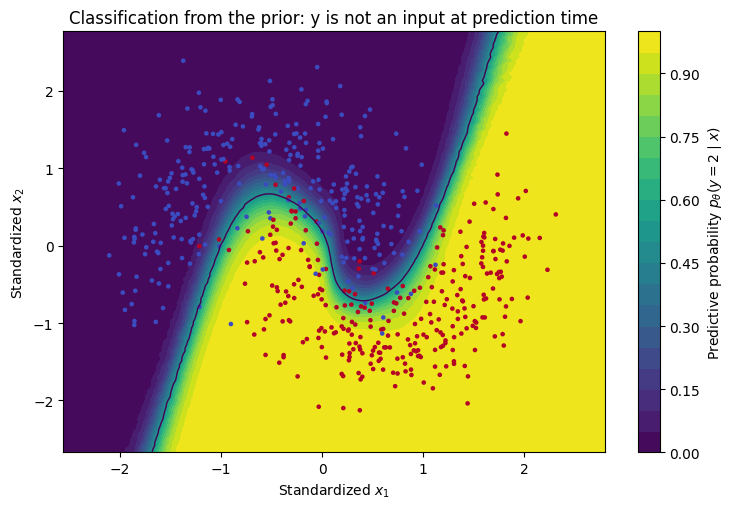

In [19]:
gx = np.linspace(moon_x[:, 0].min()-0.3, moon_x[:, 0].max()+0.3, 130)
gy = np.linspace(moon_x[:, 1].min()-0.3, moon_x[:, 1].max()+0.3, 130)
xx, yy = np.meshgrid(gx, gy)
grid_x = tensor(np.stack([xx.ravel(), yy.ravel()], axis=-1))
surface = class_probabilities(class_cvae, grid_x, S=64, seed=SEED+542)[:, 1].reshape(xx.shape).detach().cpu().numpy()
plt.figure(figsize=(7.6, 5.2))
image = plt.contourf(xx, yy, surface, levels=np.linspace(0, 1, 21), vmin=0, vmax=1)
plt.colorbar(image, label=r"Predictive probability $p_\theta(y=2\mid x)$")
plt.scatter(mx_test[:, 0].detach().cpu().numpy(),
            mx_test[:, 1].detach().cpu().numpy(), c=my_test.detach().cpu().numpy(), s=11, edgecolors="none", cmap="coolwarm")
plt.contour(xx, yy, surface, levels=[0.5], linewidths=1)
plt.xlabel(r"Standardized $x_1$")
plt.ylabel(r"Standardized $x_2$")
plt.title("Classification from the prior: y is not an input at prediction time")
show_figure("12_conditional_classification")

## 8. Conditional regression with two possible outputs

A scalar Gaussian decoder defines
$$p_\theta(y\mid x,z)=\mathcal N(y;m_\theta(x,z),\tau_\theta^2(x,z)).$$
Taking its logarithm yields
$$-\log p_\theta(y\mid x,z)=\frac12\left[
\log(2\pi)+\log\tau_\theta^2(x,z)+
\frac{(y-m_\theta(x,z))^2}{\tau_\theta^2(x,z)}\right].$$
For fixed $\tau>0$, this is scaled squared error plus a constant. When the variance is learned, the log-variance term cannot be discarded.
The conditional VAE adds the same Gaussian prior KL as in classification; only the observation model changes.

For a visible distinction between a conditional mean and a conditional distribution, generate independent observations by
$$x\sim\operatorname{Uniform}[-2,2],\quad
s_*\in\{-1,+1\}\text{ with equal probabilities},\quad
\eta\sim\mathcal N(0,1),\quad
 y=s_*a(x)+\tau_*\eta,$$
where $a(x)=0.8+0.35\cos(\pi x)$, $\tau_*=0.12$, and $x,s_*,\eta$ are independent.
Here $s_*$ is a data-generating sign, not the encoder log variance. Thus
$$p_*(y\mid x)=\tfrac12\mathcal N(y;a(x),\tau_*^2)
+\tfrac12\mathcal N(y;-a(x),\tau_*^2).$$
Summing the symmetric component means gives $\mathbb E_*[y\mid x]=0$; summing their second moments gives $\operatorname{Var}_*(y\mid x)=a(x)^2+\tau_*^2$.

The VAE uses $J=1$ and the known observation scale $\tau=0.12$. The sign $s_*$ is **not** supplied to either network. The direct reference learns a single heteroscedastic Gaussian. Both use the same train/validation/test split. A single-Gaussian reference is deliberately unable to represent two separate modes.

In [20]:
rng = np.random.default_rng(SEED+600)
reg_x = rng.uniform(-2, 2, size=(5000, 1)).astype(np.float32)
def amplitude(x):
    return 0.8+0.35*np.cos(np.pi*x)
tau_star = 0.12
signs = rng.choice([-1.0, 1.0], size=(5000, 1))
reg_y = (signs*amplitude(reg_x) + tau_star*rng.normal(size=(5000, 1))).astype(np.float32)
# Independent simulation followed by a fixed permutation; no target-based selection.
reg_order = rng.permutation(len(reg_x))
reg_train_ids, reg_val_ids, reg_test_ids = np.split(reg_order, [3000, 4000])
rx_train, rx_val, rx_test = [tensor(reg_x[i]) for i in (reg_train_ids, reg_val_ids, reg_test_ids)]
ry_train, ry_val, ry_test = [tensor(reg_y[i]) for i in (reg_train_ids, reg_val_ids, reg_test_ids)]

torch.manual_seed(SEED+610)
reg_cvae = ConditionalVAE(1, "regression", observation_sd=tau_star).to(DEVICE)
reg_history, reg_best = fit_conditional(
    reg_cvae, rx_train, ry_train, rx_val, ry_val, "regression_cvae", 220, SEED+611)
torch.manual_seed(SEED+620)
direct_reg = DirectPredictor(1, "regression").to(DEVICE)
direct_reg_best = fit_direct(direct_reg, rx_train, ry_train, rx_val, ry_val,
                             "regression_direct", 220, SEED+621)
print(f"Regression checkpoints: CVAE epoch {reg_best}, direct Gaussian epoch {direct_reg_best}.")

Regression checkpoints: CVAE epoch 218, direct Gaussian epoch 218.


### Prediction integrates the prior, not the training encoder

For this one-dimensional latent variable the conditional density can be evaluated by numerical quadrature:
$$p_\theta(y\mid x)=\int\varphi(z)\,
\mathcal N(y;m_\theta(x,z),\tau^2)\,dz,$$
where $\varphi$ is the standard normal density. Restrict the integral to $[-A,A]$, with $A=8$, and substitute $z=At$. If $t_s,w_s$ are the nodes and weights of an $S$-node Gauss–Legendre rule on $[-1,1]$, then
$$p_\theta(y\mid x)\approx\sum_{s=1}^S\bar w_s\mathcal N(y;m_\theta(x,At_s),\tau^2),\qquad
\bar w_s=\frac{A w_s\varphi(At_s)}{\sum_r A w_r\varphi(At_r)}.$$
The numerical prior weights are normalized; their unnormalized sum is checked against one. Because a Gaussian observation density is bounded above by $1/(\tau\sqrt{2\pi})$, the omitted unnormalized tail is at most $2\Phi(-A)/(\tau\sqrt{2\pi})$, where $\Phi$ is the standard normal CDF. This is below $5\times10^{-15}$ for the chosen $A$ and $\tau$. Discretization is a separate error: we compare 1024 and 2048 nodes. Agreement is a numerical diagnostic, not a proof of a quadrature error bound. The estimate is a normalized Gaussian mixture, not an unbiased Monte Carlo estimator.

The encoder receives the held-out target **only** to evaluate the held-out conditional ELBO. Predictive density and risk use the decoder and prior alone.

In [21]:
@torch.no_grad()
def regression_components(model: ConditionalVAE, x: torch.Tensor, S: int = 2048):
    nodes, weights = special.roots_legendre(S)
    weights = 8*weights*stats.norm.pdf(8*nodes)
    assert abs(weights.sum()-1.0) < 1e-11
    weights = weights/weights.sum()
    z_nodes = torch.as_tensor((8*nodes).reshape(S, 1, 1),
                              device=x.device, dtype=x.dtype)
    # Chunk the decoder so the integration grid does not set the peak memory.
    means = torch.cat([model.decode(batch, z_nodes.expand(S, len(batch), 1))
                       .squeeze(-1).double() for batch in x.split(128)], dim=1)
    weights_t = torch.as_tensor(weights, dtype=torch.float64, device=x.device)
    return means, weights_t

@torch.no_grad()
def regression_log_density(model: ConditionalVAE, x: torch.Tensor, y: torch.Tensor, S: int = 2048):
    values = []
    for start in range(0, len(x), 128):
        xb, yb = x[start:start+128], y[start:start+128]
        means, weights = regression_components(model, xb, S)
        log_component = -0.5*((yb.reshape(1, -1).double()-means)/model.observation_sd).square()
        log_component -= math.log(model.observation_sd)+0.5*math.log(2*math.pi)
        values.append(torch.logsumexp(log_component+weights.log()[:, None], dim=0))
    return torch.cat(values)

logp_1024 = regression_log_density(reg_cvae, rx_test, ry_test, S=1024)
logp_2048 = regression_log_density(reg_cvae, rx_test, ry_test, S=2048)
with torch.no_grad():
    direct_nll = direct_reg.nll(rx_test, ry_test)
    raw_direct = direct_reg.net(rx_test)
    means_test, weights_test = regression_components(reg_cvae, rx_test, S=2048)
    predictive_mean_test = (weights_test[:, None]*means_test).sum(0)
    predictive_variance_test = tau_star**2 + (weights_test[:, None]*(means_test-predictive_mean_test[None]).square()).sum(0)
true_a = amplitude(rx_test.detach().cpu().numpy()).reshape(-1)
true_y = ry_test.detach().cpu().numpy().reshape(-1)
true_logp = special.logsumexp(np.stack([
    stats.norm.logpdf(true_y, true_a, tau_star),
    stats.norm.logpdf(true_y, -true_a, tau_star)], axis=0), axis=0)-np.log(2)
reg_elbo = evaluate_conditional(reg_cvae, rx_test, ry_test, L=128, seed=SEED+630)
reg_rows = [
    {"model": "Conditional VAE (2048-node prior integral)", "predictive_NLL": -logp_2048.mean().item(),
     "mean_RMSE": torch.mean((predictive_mean_test-ry_test.reshape(-1).double()).square()).sqrt().item()},
    {"model": "Single conditional Gaussian", "predictive_NLL": direct_nll.mean().item(),
     "mean_RMSE": torch.mean((raw_direct[:, 0]-ry_test.reshape(-1)).square()).sqrt().item()},
    {"model": "Known data-generating mixture", "predictive_NLL": -float(true_logp.mean()),
     "mean_RMSE": float(np.sqrt(np.mean(true_y**2)))},
]
results["regression"] = {"metrics": reg_rows, "negative_elbo": reg_elbo[0],
    "reconstruction_nll": reg_elbo[1], "kl": reg_elbo[2], "best_epoch": reg_best,
    "quadrature_mean_abs_difference": (logp_1024-logp_2048).abs().mean().item(),
    "quadrature_max_abs_difference": (logp_1024-logp_2048).abs().max().item(),
    "N_train": len(rx_train), "N_val": len(rx_val), "N_test": len(rx_test)}
display(pd.DataFrame(reg_rows).set_index("model").round(4))
print(f"Conditional negative ELBO: {reg_elbo[0]:.4f}; KL: {reg_elbo[2]:.4f} nats per pair.")
print(f"1024 vs 2048 nodes: mean |difference in log density| = {results['regression']['quadrature_mean_abs_difference']:.5g}")

,predictive_NLL,mean_RMSE
model,,
Conditional VAE (2048-node prior integral),0.2767,0.8484
Single conditional Gaussian,1.1581,0.8502
Known data-generating mixture,-0.0086,0.8477


Conditional negative ELBO: 0.6194; KL: 1.2209 nats per pair.
1024 vs 2048 nodes: mean |difference in log density| = 7.1369e-08


### The learned conditional density

The heat map displays the density obtained by integrating prior nodes. Dashed curves mark the two means of the data-generating components, $\pm a(x)$. A conditional mean near zero can have a good squared-error risk while lying between the two likely outcomes. Thus RMSE alone cannot evaluate whether a model has learned the conditional distribution.

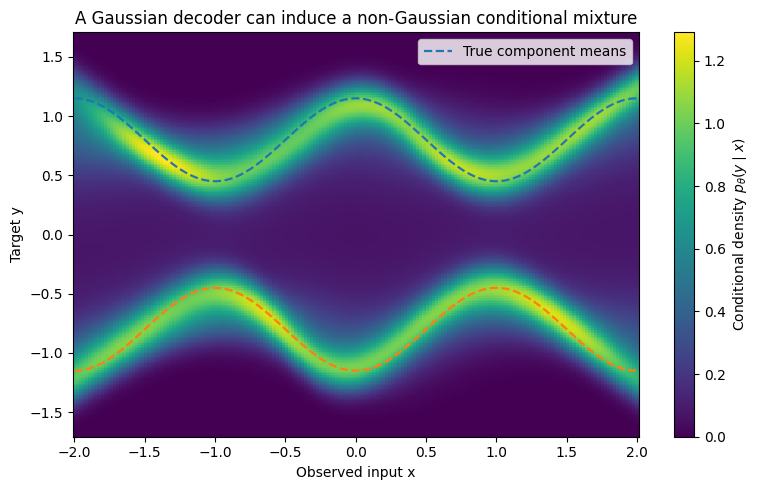

In [22]:
plot_x = tensor(np.linspace(-2, 2, 181, dtype=np.float32).reshape(-1, 1))
plot_y = np.linspace(-1.7, 1.7, 241)
with torch.no_grad():
    grid_means, grid_weights = regression_components(reg_cvae, plot_x, S=2048)
    density_columns = []
    for j in range(len(plot_x)):
        component = stats.norm.pdf(plot_y[:, None], loc=grid_means[:, j].detach().cpu().numpy()[None], scale=tau_star)
        density_columns.append(component @ grid_weights.detach().cpu().numpy())
    learned_density = np.stack(density_columns, axis=1)
plt.figure(figsize=(8.0, 5.0))
img = plt.pcolormesh(plot_x.detach().cpu().numpy().ravel(), plot_y, learned_density, shading="auto")
plt.colorbar(img, label=r"Conditional density $p_\theta(y\mid x)$")
plt.plot(plot_x.detach().cpu().numpy().ravel(), amplitude(plot_x.detach().cpu().numpy()).ravel(), "--", linewidth=1.6, label="True component means")
plt.plot(plot_x.detach().cpu().numpy().ravel(), -amplitude(plot_x.detach().cpu().numpy()).ravel(), "--", linewidth=1.6)
plt.xlabel("Observed input x")
plt.ylabel("Target y")
plt.title("A Gaussian decoder can induce a non-Gaussian conditional mixture")
plt.legend()
show_figure("13_regression_density")

### One conditional slice

At $x=0$, compare the entire predictive density with the known mixture and with the single-Gaussian reference. The conditional VAE is not given the two mixture labels; it learns a continuous latent representation from the pairs $(x,y)$.

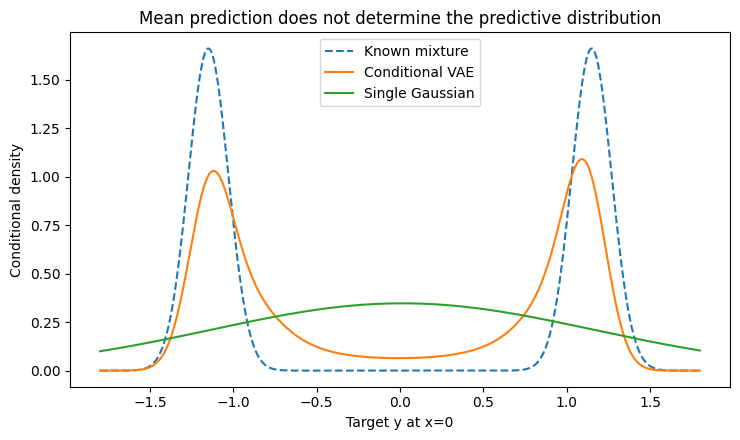

In [23]:
x_slice = tensor(np.array([[0.0]], dtype=np.float32))
with torch.no_grad():
    slice_means, slice_weights = regression_components(reg_cvae, x_slice, S=2048)
    slice_raw = direct_reg.net(x_slice)
    slice_direct_mean = slice_raw[0, 0].item()
    slice_direct_sd = (F.softplus(slice_raw[0, 1])+0.03).item()
y_slice = np.linspace(-1.8, 1.8, 600)
slice_density = stats.norm.pdf(y_slice[:, None], slice_means[:, 0].detach().cpu().numpy()[None], tau_star) @ slice_weights.detach().cpu().numpy()
true_slice = 0.5*(stats.norm.pdf(y_slice, amplitude(0.0), tau_star)+stats.norm.pdf(y_slice, -amplitude(0.0), tau_star))
plt.figure(figsize=(7.5, 4.5))
plt.plot(y_slice, true_slice, linestyle="--", label="Known mixture")
plt.plot(y_slice, slice_density, label="Conditional VAE")
plt.plot(y_slice, stats.norm.pdf(y_slice, slice_direct_mean, slice_direct_sd), label="Single Gaussian")
plt.xlabel("Target y at x=0")
plt.ylabel("Conditional density")
plt.title("Mean prediction does not determine the predictive distribution")
plt.legend()
show_figure("14_regression_slice")

### Predictive variance and its interpretation

The identities $\mathbb E[y\mid x,z]=m_\theta(x,z)$ and
$\mathbb E[y^2\mid x,z]=\tau_\theta^2(x,z)+m_\theta^2(x,z)$ imply, after integrating the prior and subtracting the squared mean,
$$\begin{aligned}
\mathbb E[y\mid x]&=\mathbb E_{p_\theta(z\mid x)}m_\theta(x,z),\\
\operatorname{Var}(y\mid x)&=\mathbb E_{p_\theta(z\mid x)}\tau_\theta^2(x,z)
+\operatorname{Var}_{p_\theta(z\mid x)}m_\theta(x,z).
\end{aligned}$$
Both terms belong to the predictive distribution of a **fixed fitted model**. The second is not automatically epistemic uncertainty about $\theta$. The mean minimizes squared-error risk because
$\mathbb E[(y-c)^2\mid x]=\operatorname{Var}(y\mid x)+(c-\mathbb E[y\mid x])^2$.
For a non-Gaussian mixture, mean $\pm1.96$ standard deviations is not generally a 95% prediction interval; quantiles must be computed from the mixture itself.

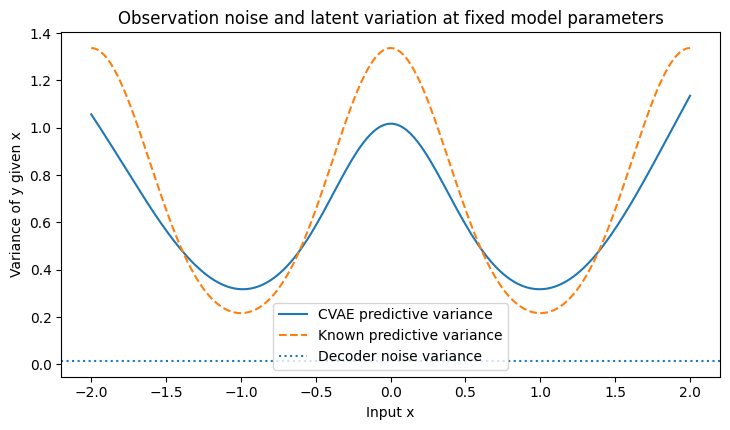

In [24]:
with torch.no_grad():
    means_grid, weights_grid = regression_components(reg_cvae, plot_x, S=2048)
    conditional_mean = (weights_grid[:, None]*means_grid).sum(0)
    between_variance = (weights_grid[:, None]*(means_grid-conditional_mean[None]).square()).sum(0)
    total_variance = between_variance+tau_star**2
np.testing.assert_allclose(total_variance.detach().cpu().numpy(), between_variance.detach().cpu().numpy()+tau_star**2, atol=1e-12)
plt.figure(figsize=(7.4, 4.4))
plt.plot(plot_x.detach().cpu().numpy().ravel(), total_variance.detach().cpu().numpy(), label="CVAE predictive variance")
plt.plot(plot_x.detach().cpu().numpy().ravel(), amplitude(plot_x.detach().cpu().numpy()).ravel()**2+tau_star**2,
         linestyle="--", label="Known predictive variance")
plt.axhline(tau_star**2, linestyle=":", label="Decoder noise variance")
plt.xlabel("Input x")
plt.ylabel("Variance of y given x")
plt.title("Observation noise and latent variation at fixed model parameters")
plt.legend()
show_figure("15_predictive_variance")

## 9. An optional bridge to semi-supervised classification

The 2014 semi-supervised paper uses a different joint factorization, often called M2:
$$p_\theta(x,y,z)=p(y)p(z)p_\theta(x\mid y,z),\qquad
q_\phi(y,z\mid x)=q_\phi(y\mid x)q_\phi(z\mid x,y).$$
For a labeled pair, the joint ELBO in the maximization convention of [KW] is
$$\mathcal L_l(x,y)=\log p(y)+\mathbb E_{q_\phi(z\mid x,y)}\log p_\theta(x\mid y,z)
-D_{\rm KL}(q_\phi(z\mid x,y)\|p(z)).$$
For an unlabeled observation, expand $\log q_\phi(y,z\mid x)$ into its two factors and sum over $y$:
$$\begin{aligned}
\mathcal L_u(x)
&=\sum_{k=1}^{K}q_\phi(k\mid x)\,
\mathbb E_{q_\phi(z\mid x,k)}
[\log p_\theta(x,k,z)-\log q_\phi(z\mid x,k)-\log q_\phi(k\mid x)]\\
&=\sum_{k=1}^K q_\phi(k\mid x)\mathcal L_l(x,k)
+H(q_\phi(y\mid x)),
\end{aligned}$$
where $H(r)=-\sum_k r_k\log r_k$. For modest $K$, the class sum is exact; no pathwise derivative through a sampled class is required.

In this fixed model the labeled ELBO does not involve the separate classifier $q_\phi(y\mid x)$. The 2014 construction adds a weighted labeled classification objective. That addition must be distinguished from simply expanding the same joint ELBO. The paper uses negative-loss signs; the formulas above retain [KW]'s maximization sign.

This cell verifies the entropy decomposition on arbitrary class scores. It does **not** train an M2 model or reproduce semi-supervised benchmark results.

In [25]:
class_logits = torch.tensor([[0.2, -0.4, 1.0], [0.3, 0.1, -0.2]], dtype=torch.float64, device="cpu")
labeled_bounds = torch.tensor([[-10.0, -14.0, -9.0], [-8.0, -8.5, -11.0]], dtype=torch.float64, device="cpu")
log_prob_class = class_logits.log_softmax(-1)
prob_class = log_prob_class.exp()
unlabeled_direct = (prob_class*(labeled_bounds-log_prob_class)).sum(-1)
class_entropy = -(prob_class*log_prob_class).sum(-1)
unlabeled_decomposed = (prob_class*labeled_bounds).sum(-1)+class_entropy
assert torch.allclose(unlabeled_direct, unlabeled_decomposed, atol=1e-12)
print("Finite-class ELBO/entropy decomposition verified.")

Finite-class ELBO/entropy decomposition verified.


## 10. Checks and experiment record

The analytic checks test the ELBO identity, numerical evidence integration, Gaussian KL and its gradients, reparameterized differentiation, normalized class probabilities, and the finite-label entropy decomposition. Neural training is nonconvex; none of these tests asserts global optimality or an improvement over every baseline.

Train/validation/test splits are fixed. Validation selects checkpoints; test data are used for the reported evaluation and plots only. The regression quadrature comparison is an integration diagnostic, not a confidence interval. Reproducibility across different library versions, processors, or thread counts need not be bitwise exact.

Device checks verify the placement of all six models, their inputs and targets, and the regression quadrature weights. Random generators are constructed on the device where their draws are allocated. Checkpoints store CPU tensors and are loaded onto the selected model device. The first code cell configures cuBLAS before CUDA initialization because deterministic matrix products require this setting; restart the kernel when changing execution settings. See the PyTorch documentation for [generators](https://docs.pytorch.org/docs/2.4/generated/torch.Generator.html), [deterministic algorithms](https://docs.pytorch.org/docs/2.4/generated/torch.use_deterministic_algorithms.html), and [reproducibility](https://docs.pytorch.org/docs/2.4/notes/randomness.html).

In [26]:
# Every trained model and each of its data tensors must use the same device.
model_data_groups = [
    (vae2, (x_train, x_val, x_test)),
    (vae8, (x_train, x_val, x_test)),
    (class_cvae, (mx_train, mx_val, mx_test, my_train, my_val, my_test)),
    (direct_class, (mx_train, mx_val, mx_test, my_train, my_val, my_test)),
    (reg_cvae, (rx_train, rx_val, rx_test, ry_train, ry_val, ry_test)),
    (direct_reg, (rx_train, rx_val, rx_test, ry_train, ry_val, ry_test)),
]
for model, arrays in model_data_groups:
    model_device = next(model.parameters()).device
    assert all(parameter.device == model_device for parameter in model.parameters())
    assert all(array.device == model_device for array in arrays)
assert weights_test.device == means_test.device == rx_test.device
results["device_checks"] = {"passed": True, "device": str(x_train.device)}
if DEVICE.type == "cuda":
    torch.cuda.synchronize(DEVICE)

results["elapsed_seconds"] = time.perf_counter()-run_started
results["settings"] = {
    "TRAIN": TRAIN, "device": str(DEVICE), "threads": torch.get_num_threads(),
    "vae_hidden": 128, "vae_epochs": 260, "vae_batch": 100, "vae_L_train": 1,
    "conditional_hidden": [64, 64], "conditional_batch": 128,
    "classifier_epochs": 130, "regression_epochs": 220,
    "optimizer": "Adam", "learning_rate": 0.001,
    "kl_coefficient": 1.0, "weight_decay": 0.0,
}
Path("results.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
# Every figure in the notebook is created by one of the preceding cells.
assert len(list(FIG_DIR.glob("*.png"))) >= 15
assert all(np.isfinite(row["negative_elbo"]) for row in results["vae"])
assert np.isfinite(results["regression"]["negative_elbo"])
print(f"Execution complete in {results['elapsed_seconds']:.1f} seconds.")
print("Results: results.json | Figures: figures/ | Model states: checkpoints/")

Execution complete in 101.8 seconds.
Results: results.json | Figures: figures/ | Model states: checkpoints/


## References and scope

**[KW]** D. P. Kingma and M. Welling. *Auto-Encoding Variational Bayes*. arXiv:1312.6114, version 11, 10 December 2022; first submitted in 2013. The seminar is based on the supplied version. Sections 2.1–2.4: model, ELBO, SGVB and AEVB; Section 3 and Appendices B–C: Gaussian encoder and Bernoulli/Gaussian decoders; Appendix A: visualizations. https://arxiv.org/abs/1312.6114

**Conditional extension.** K. Sohn, H. Lee and X. Yan. *Learning Structured Output Representation using Deep Conditional Generative Models*. NeurIPS 28, 2015, Section 4. The supervised datasets, architectures and numerical results here are newly constructed teaching examples. https://papers.nips.cc/paper_files/paper/2015/hash/8d55a249e6baa5c06772297520da2051-Abstract.html

**Semi-supervised extension.** D. P. Kingma, D. J. Rezende, S. Mohamed and M. Welling. *Semi-Supervised Learning with Deep Generative Models*. NeurIPS 27, 2014; arXiv:1406.5298, Section 3. The notebook verifies the finite-label identity but does not run the paper's M2 experiments. https://arxiv.org/abs/1406.5298

**Data.** `sklearn.datasets.load_digits`: the UCI optical-recognition digit data supplied with scikit-learn; 1,797 images, 64 integer-valued features in $[0,16]$. The data and binarization used here are not MNIST. https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html

**Implementation.** PyTorch 2.10 distribution documentation, in particular pathwise derivatives, `Normal.rsample()` and `kl_divergence`. The execution cell records the installed versions rather than asserting that they are the latest. https://docs.pytorch.org/docs/2.10/distributions.html

The exact scalar model, the correlated-Gaussian calculation, the gradient-variance calculation, the importance-weight diagnostic, and the synthetic regression distribution are mathematical teaching constructions. Their equations are derived in the notebook and in the accompanying notes; they are not attributed to experimental claims in [KW].